# Imports

In [1]:
import torch 
import torch.nn as nn
import math
from typing import List, Union
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from torch.utils.data import Dataset 

from torch.utils.data import DataLoader
import random
import seaborn as sns
import pickle
from torch.nn.utils.rnn import pad_sequence
import pandas as pd
from PIL import Image
import glob
import os

from matplotlib.gridspec import GridSpec
import matplotlib.colors as mcolors

In [2]:
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

In [3]:
###

## aux func

In [4]:
def save_coss_with_tag(model, tag):
    with torch.no_grad():
        # matriz de embeddings normalizada [V, D]
        E = F.normalize(model.embedding.weight, dim=1)
        
        # produto interno de todos com todos => coseno (pois já normalizado)
        sim_matrix = E @ E.T   # [V, V]
        coss = pd.DataFrame(sim_matrix.cpu().numpy())
        coss.to_csv(f"cosine_similarity_matrix_gpt_{tag}.csv",index=False, header=True)
    return

In [5]:
@torch.no_grad()
def snapshot_transformer_forward(model, seq_ids, layer_idx=0):
    model.eval()

    x = torch.tensor([seq_ids], dtype=torch.long, device=model.embedding.weight.device)  # [1, T]
    B, T = x.shape
    layer = model.encoder.layers[layer_idx]


    W_linear1 = layer.linear1.weight         # [D_ff, D]
    b_linear1 = layer.linear1.bias           # [D_ff]

    W_linear2 = layer.linear2.weight         # [D, D_ff]
    b_linear2 = layer.linear2.bias           # [D]

    W_fc_out = model.fc_out.weight           # [V, D]
    b_fc_out = model.fc_out.bias             # [V]


    key_padding_mask = (x == model.pad_token_id)

    tok_emb = model.embedding(x)  # [1, T, D]

    if isinstance(model.position_embedding, torch.nn.Embedding):
        pos_ids = torch.arange(T, device=x.device).unsqueeze(0).expand(B, T)
        pos_emb = model.position_embedding(pos_ids)
        h0 = tok_emb + pos_emb
    else:
        h0 = model.position_embedding(tok_emb)
        pos_emb = h0 - tok_emb

    attn_mask = model._causal_mask(T, x.device) if getattr(model, "causal", False) else None

    D = model.embedding.embedding_dim

    W = layer.self_attn.in_proj_weight
    b = layer.self_attn.in_proj_bias

    W_q = W[:D]
    W_k = W[D:2*D]
    W_v = W[2*D:3*D]

    b_q = b[:D]
    b_k = b[D:2*D]
    b_v = b[2*D:3*D]

    qkv = F.linear(h0, W, b)                      # [1, T, 3D]
    q, k, v = qkv.chunk(3, dim=-1)               # [1, T, D] cada

    # Similaridade bruta S = QK^T / sqrt(D)
    s_raw = torch.matmul(q, k.transpose(-2, -1)) / np.sqrt(D)   # [1, T, T]

    # Aplicar máscaras manualmente para obter versão pré-softmax mascarada
    s_masked = s_raw.clone()

    if attn_mask is not None:
        # attn_mask: [T, T] com True onde deve mascarar
        s_masked = s_masked.masked_fill(attn_mask.unsqueeze(0), float("-inf"))

    if key_padding_mask is not None:
        # mascara colunas correspondentes a PAD
        s_masked = s_masked.masked_fill(key_padding_mask.unsqueeze(1), float("-inf"))

    # Atenção pós-softmax
    attn_probs = torch.softmax(s_masked, dim=-1)  # [1, T, T]

    attn_out, attn_w = layer.self_attn(
        h0, h0, h0,
        attn_mask=attn_mask,
        key_padding_mask=key_padding_mask,
        need_weights=True,
        average_attn_weights=False
    )                                             # attn_w: [1, H, T, T]

    x1 = layer.norm1(h0 + layer.dropout1(attn_out))

    ff1 = layer.linear1(x1)
    act = layer.activation(ff1)
    ff2 = layer.linear2(layer.dropout(act))

    x2 = layer.norm2(x1 + layer.dropout2(ff2))

    logits = model.fc_out(x2)

    probs = torch.softmax(logits, dim=-1)
    pred_ids = torch.argmax(logits, dim=-1)

    return {
        "tokens": x[0].detach().cpu().numpy(),

        "token_embedding": tok_emb[0].detach().cpu().numpy(),
        "position_embedding": pos_emb[0].detach().cpu().numpy(),
        "embedding_plus_position": h0[0].detach().cpu().numpy(),
        'embedded_data': model.embedding.weight.cpu().detach().numpy(),

        "W_q": W_q.detach().cpu().numpy(),
        "W_k": W_k.detach().cpu().numpy(),
        "W_v": W_v.detach().cpu().numpy(),

        "b_q": b_q.detach().cpu().numpy(),
        "b_k": b_k.detach().cpu().numpy(),
        "b_v": b_v.detach().cpu().numpy(),

        "q": q[0].detach().cpu().numpy(),
        "k": k[0].detach().cpu().numpy(),
        "v": v[0].detach().cpu().numpy(),

        "similarity_raw": s_raw[0].detach().cpu().numpy(),        # antes de máscaras
        "similarity_masked": s_masked[0].detach().cpu().numpy(),  # após máscaras, antes do softmax
        "attention_probs": attn_probs[0].detach().cpu().numpy(),  # softmax(S)

        "attention_output": attn_out[0].detach().cpu().numpy(),
        "after_attention_block": x1[0].detach().cpu().numpy(),

        "linear1": ff1[0].detach().cpu().numpy(),
        "activation": act[0].detach().cpu().numpy(),
        "linear2": ff2[0].detach().cpu().numpy(),
        "after_ffn_block": x2[0].detach().cpu().numpy(),

        "logits": logits[0].detach().cpu().numpy(),

        "attn_weights": attn_w[0].detach().cpu().numpy(),  # [H, T, T]
        "attention_weighted_values": (attn_probs @ v)[0].detach().cpu().numpy(),

        "W_linear1": W_linear1.detach().cpu().numpy(),
        "b_linear1": b_linear1.detach().cpu().numpy(),

        "W_linear2": W_linear2.detach().cpu().numpy(),
        "b_linear2": b_linear2.detach().cpu().numpy(),

        "W_fc_out": W_fc_out.detach().cpu().numpy(),
        "b_fc_out": b_fc_out.detach().cpu().numpy(),
        "probs": probs[0].detach().cpu().numpy(),
        "pred_ids": pred_ids[0].detach().cpu().numpy(),
    }

# Dataset

In [6]:
df = pd.read_parquet(r'/home/mgteus/workspace/navitrans/sargolini_trainset_squared_25.gzip')
print(df.shape)
df.head(2)

(2684, 11)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.8195847065625171, 0.21282334198892955]",0.022236,"[0.039705410337458336, -0.14096142486541452]",9.178052,"[0.8579642766522511, -0.5137093536121176]",YGWPVLKJTKVXGFLVPIPZ,769,0.997406,770.0,1
1,0.40,"[0.8084176057915655, 0.1833762902898712]",0.055311,"[-0.06548091434677383, -0.09602170424236667]",1.701201,"[-0.26195302935619863, -0.965080623788039]",YGWPTKVXVLKJGFLVPIPZ,751,0.974060,769.0,1


### tokenized dataset

In [7]:
# with open('ps_to_psid.pkl', 'rb') as file:
#     ps_to_psid = pickle.load(file)

In [8]:
df['position_state_id'] = df.groupby('position_state_id').ngroup()+1

df['position_state_id'].min(), df['position_state_id'].max(), df['position_state_id'].nunique()

(1, 771, 771)

#### vocab size

In [9]:
df['position_state_id'].nunique()

771

#### token freqs

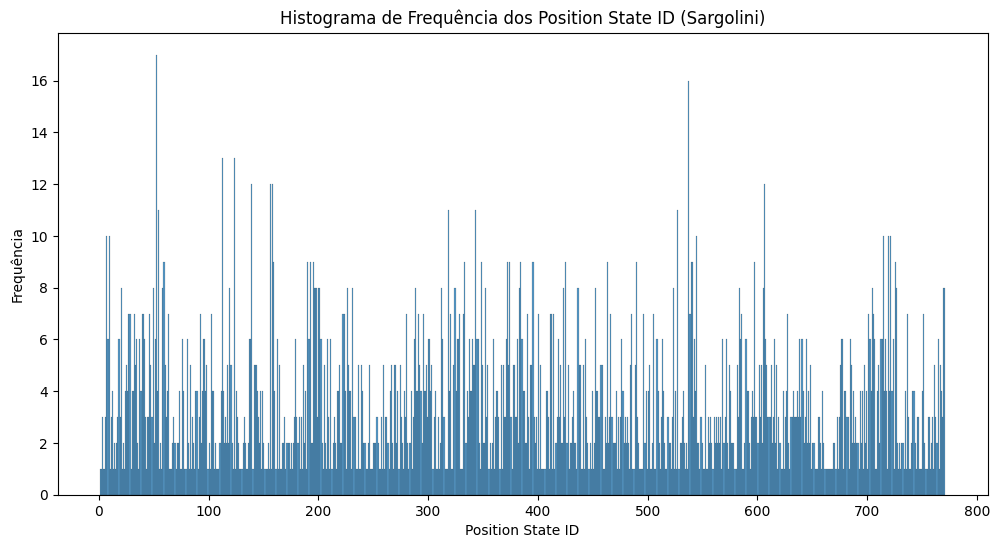

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.title('Histograma de Frequência dos Position State ID (Sargolini)')
sns.histplot(df['position_state_id'],binwidth=1,)
plt.ylabel('Frequência')
plt.xlabel('Position State ID')
plt.show()

# Classes

In [11]:
def collate_masked_batch(batch, pad_token_id=0):
    xs, ys = zip(*batch)
    x = pad_sequence(xs, batch_first=True, padding_value=pad_token_id)
    y = pad_sequence(ys, batch_first=True, padding_value=-100)
    # attention_mask: 1 onde não é PAD
    attention_mask = (x != pad_token_id).long()
    return x, y, attention_mask

### dataset class

In [12]:
class TrajectoryARDataset_RandLen(Dataset):
    def __init__(
        self,
        full_sequence,
        min_len=4,
        max_len=32,
        bos_token_id=None,
        eos_token_id=None,
    ):
        """
        Autoregressivo: para cada janela, x = tokens[0..T-2], y = tokens[1..T-1].
        """
        assert min_len >= 2, "min_len precisa ser ≥ 2 para AR"
        self.full_sequence = list(full_sequence)
        if bos_token_id is not None:
            self.full_sequence = [bos_token_id] + self.full_sequence
        if eos_token_id is not None:
            self.full_sequence = self.full_sequence + [eos_token_id]

        self.min_len = min_len
        self.max_len = max_len

        # garante que ainda há pelo menos min_len tokens a partir de start
        self.start_indices = list(range(0, max(1, len(self.full_sequence) - self.min_len)))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        seq_len = random.randint(self.min_len, self.max_len)
        end = min(start + seq_len, len(self.full_sequence))
        seq = self.full_sequence[start:end]

        # força pelo menos 2 tokens (raríssimo não cumprir devido à construção de start_indices)
        if len(seq) < 2:
            end = min(start + 2, len(self.full_sequence))
            seq = self.full_sequence[start:end]

        x = torch.tensor(seq[:-1], dtype=torch.long)  # input
        y = torch.tensor(seq[1:],  dtype=torch.long)  # alvo (próximo token)
        return x, y


In [13]:
class TrajectoryARDataset_FixLen(Dataset):
    def __init__(
        self,
        full_sequence,
        max_len=32,
        pad_token_id=947,
        bos_token_id=None,
        eos_token_id=None,
    ):
        self.full_sequence = list(full_sequence)

        if bos_token_id is not None:
            self.full_sequence = [bos_token_id] + self.full_sequence
        if eos_token_id is not None:
            self.full_sequence = self.full_sequence + [eos_token_id]

        self.max_len = max_len
        self.pad_token_id = pad_token_id

        self.start_indices = list(range(len(self.full_sequence)))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        end = start + self.max_len

        seq = self.full_sequence[start:end]

        if len(seq) < self.max_len:
            seq = seq + [self.pad_token_id] * (self.max_len - len(seq))

        x = torch.tensor(seq[:-1], dtype=torch.long)
        y = torch.tensor(seq[1:],  dtype=torch.long)
        return x, y

In [14]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe)  # não é treinável

    def forward(self, x):
        # x: [B, T, D]
        T = x.size(1)
        return x + self.pe[:T].unsqueeze(0)

### model class

In [15]:
class TrajectoryBERT_HardPos(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size,
        num_layers,
        num_heads,
        hidden_dim,
        dropout=0.1,
        max_len=512,
        pad_token_id=0,
        causal=False,
    ):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_len = max_len
        self.causal = causal

        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=pad_token_id)
        self.position_embedding = PositionalEncoding(embed_size, max_len)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    @staticmethod
    def _causal_mask(T, device):
        return torch.triu(torch.ones(T, T, device=device, dtype=torch.bool), diagonal=1)

    def forward(self, x, attention_mask: torch.Tensor = None):
        """
        x: [B, T] com IDs de token
        attention_mask: [B, T], 1=valido, 0=PAD
        """
        B, T = x.size()
        device = x.device

        if T > self.max_len:
            x = x[:, -self.max_len:]
            T = self.max_len
            if attention_mask is not None:
                attention_mask = attention_mask[:, -self.max_len:]

        if attention_mask is None:
            key_padding_mask = (x == self.pad_token_id)
        else:
            key_padding_mask = (attention_mask == 0)
            if attention_mask.dtype == torch.bool:
                key_padding_mask = ~attention_mask

        h = self.embedding(x)
        h = self.position_embedding(h)

        src_mask = self._causal_mask(T, device) if self.causal else None

        h = self.encoder(h, mask=src_mask, src_key_padding_mask=key_padding_mask)
        logits = self.fc_out(h)
        return logits

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens=50, eos_token_id=None, temperature=1.0, top_k=None):
        assert self.causal, "Ative causal=True para gerar de forma autoregressiva."
        self.eval()
        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        for _ in range(max_new_tokens):
            logits = self.forward(x)[:, -1, :]
            logits = logits / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                vals, idxs = torch.topk(logits, k=top_k, dim=-1)
                filt = torch.full_like(logits, float("-inf"))
                logits = filt.scatter(1, idxs, vals)

            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        return x.squeeze(0)

    @torch.no_grad()
    def generate_with_distributions(
        self,
        prompt_ids: torch.Tensor,
        max_new_tokens: int = 50,
        eos_token_id: int = None,
        temperature: float = 1.0,
        top_k: int = None,
        return_logits: bool = False,
        return_raw_logits: bool = False,
        to_cpu: bool = True,
    ):
        assert self.causal, "Ative causal=True para geração autoregressiva."
        self.eval()

        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        probs_list = []
        logits_list = [] if return_logits else None
        logits_raw_list = [] if return_raw_logits else None

        for _ in range(max_new_tokens):
            logits_raw = self.forward(x)[:, -1, :].squeeze(0)
            logits_adj = logits_raw / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                k = min(top_k, logits_adj.shape[-1])
                vals, idxs = torch.topk(logits_adj, k=k, dim=-1)
                tmp = torch.full_like(logits_adj, float("-inf"))
                logits_adj = tmp.scatter(0, idxs, vals)

            probs = torch.softmax(logits_adj, dim=-1)

            target_device = torch.device("cpu") if to_cpu else device
            probs_list.append(probs.detach().to(target_device))
            if return_logits:
                logits_list.append(logits_adj.detach().to(target_device))
            if return_raw_logits:
                logits_raw_list.append(logits_raw.detach().to(target_device))

            next_id = torch.multinomial(probs.unsqueeze(0), num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        out_tokens = x.squeeze(0)
        dists = {"probs": torch.stack(probs_list, dim=0)}
        if return_logits:
            dists["logits"] = torch.stack(logits_list, dim=0)
        if return_raw_logits:
            dists["logits_raw"] = torch.stack(logits_raw_list, dim=0)

        return out_tokens, dists

In [16]:
class TrajectoryBERTLearnedPos(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size,
        num_layers,
        num_heads,
        hidden_dim,
        dropout=0.1,
        max_len=512,
        pad_token_id=0,
        causal=False,
    ):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_len = max_len
        self.causal = causal

        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=pad_token_id)
        self.position_embedding = nn.Embedding(max_len, embed_size)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    @staticmethod
    def _causal_mask(T, device):
        return torch.triu(torch.ones(T, T, device=device, dtype=torch.bool), diagonal=1)

    def forward(self, x, attention_mask: torch.Tensor = None):
        """
        x: [B, T] com IDs de token
        attention_mask: [B, T], 1=valido, 0=PAD
        """
        B, T = x.size()
        device = x.device

        if T > self.max_len:
            x = x[:, :self.max_len]
            T = self.max_len
            if attention_mask is not None:
                attention_mask = attention_mask[:, :self.max_len]

        if attention_mask is None:
            key_padding_mask = (x == self.pad_token_id)
        else:
            key_padding_mask = (attention_mask == 0)
            if attention_mask.dtype == torch.bool:
                key_padding_mask = ~attention_mask

        pos_ids = torch.arange(T, device=device).unsqueeze(0).expand(B, T)

        h = self.embedding(x) + self.position_embedding(pos_ids)

        src_mask = self._causal_mask(T, device) if self.causal else None

        h = self.encoder(h, mask=src_mask, src_key_padding_mask=key_padding_mask)
        logits = self.fc_out(h)
        return logits

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens=50, eos_token_id=None, temperature=1.0, top_k=None):
        assert self.causal, "Ative causal=True para gerar de forma autoregressiva."
        self.eval()
        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        for _ in range(max_new_tokens):
            logits = self.forward(x)[:, -1, :]
            logits = logits / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                vals, idxs = torch.topk(logits, k=top_k, dim=-1)
                filt = torch.full_like(logits, float("-inf"))
                logits = filt.scatter(1, idxs, vals)

            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        return x.squeeze(0)

    @torch.no_grad()
    def generate_with_distributions(
        self,
        prompt_ids: torch.Tensor,
        max_new_tokens: int = 50,
        eos_token_id: int = None,
        temperature: float = 1.0,
        top_k: int = None,
        return_logits: bool = False,
        return_raw_logits: bool = False,
        to_cpu: bool = True,
    ):
        assert self.causal, "Ative causal=True para geração autoregressiva."
        self.eval()

        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        probs_list = []
        logits_list = [] if return_logits else None
        logits_raw_list = [] if return_raw_logits else None

        for _ in range(max_new_tokens):
            logits_raw = self.forward(x)[:, -1, :].squeeze(0)
            logits_adj = logits_raw / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                k = min(top_k, logits_adj.shape[-1])
                vals, idxs = torch.topk(logits_adj, k=k, dim=-1)
                tmp = torch.full_like(logits_adj, float("-inf"))
                logits_adj = tmp.scatter(0, idxs, vals)

            probs = torch.softmax(logits_adj, dim=-1)

            target_device = torch.device("cpu") if to_cpu else device
            probs_list.append(probs.detach().to(target_device))
            if return_logits:
                logits_list.append(logits_adj.detach().to(target_device))
            if return_raw_logits:
                logits_raw_list.append(logits_raw.detach().to(target_device))

            next_id = torch.multinomial(probs.unsqueeze(0), num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        out_tokens = x.squeeze(0)
        dists = {"probs": torch.stack(probs_list, dim=0)}
        if return_logits:
            dists["logits"] = torch.stack(logits_list, dim=0)
        if return_raw_logits:
            dists["logits_raw"] = torch.stack(logits_raw_list, dim=0)

        return out_tokens, dists

# Definitions

In [17]:
# Hiperparâmetros
embed_size = 16
num_layers = 1
num_heads = 1
hidden_dim = 32
mask_token_id = df['position_state_id'].max() 
pad_token_id = df['position_state_id'].max() + 1
vocab_size = pad_token_id + 1
max_len = 10
dropout = 0.2
batch_size = 256
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 1e3
# Simulando dados
sequences = df['position_state_id'].values

device, vocab_size

(device(type='cuda'), 773)

In [18]:
df['position_state_id'].max()

771

In [19]:
max_len

10

In [20]:
sequences

array([769, 751, 612, ..., 419, 770, 769])

In [21]:
mask_token_id, pad_token_id

(771, 772)

# Model

### init datasets

In [22]:
# help(torch.utils.data.random_split)

In [23]:
# [Célula] Dataset e dataloaders
dataset = TrajectoryARDataset_FixLen(
    full_sequence=sequences,   # sua sequência única (lista de ids)
    max_len=max_len,           # seu valor existente
    bos_token_id=None,
    pad_token_id=pad_token_id,
    eos_token_id=None,
)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size], )

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)
val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)

model_tag = 'HardPos_Sargolini'

In [24]:
model_tag

'HardPos_Sargolini'

In [25]:
batch = next(iter(train_loader))

x = batch["input_ids"] if isinstance(batch, dict) else batch[0]
y = batch["labels"] if isinstance(batch, dict) else batch[1]

print("vocab_size:", vocab_size)
print("pad_token_id:", pad_token_id)
print("mask_token_id:", mask_token_id)

print("x min:", x.min().item())
print("x max:", x.max().item())

valid_y = y[y != -100]
print("y min:", valid_y.min().item())
print("y max:", valid_y.max().item())

print("IDs inválidos em x:", torch.unique(x[x >= vocab_size]))
print("IDs inválidos em y:", torch.unique(valid_y[valid_y >= vocab_size]))

vocab_size: 773
pad_token_id: 772
mask_token_id: 771
x min: 3
x max: 772
y min: 3
y max: 772
IDs inválidos em x: tensor([], dtype=torch.int64)
IDs inválidos em y: tensor([], dtype=torch.int64)


### init model

In [26]:
# [Célula] Inicialização do modelo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TrajectoryBERT_HardPos(
    vocab_size,
    embed_size=embed_size,
    num_layers=num_layers,
    num_heads=num_heads,
    hidden_dim=hidden_dim,
    dropout=dropout,
    pad_token_id=pad_token_id,
    max_len=max_len,   # ajuste se necessário
    causal= True
).to(device)

/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


### init optim and loss

In [27]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Params: {trainable_params}")

Total Trainable Params: 27733


In [28]:
# [Célula] Otimizador e critério
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
# per-token para conseguirmos média apenas nos alvos válidos (-100 é ignorado)
criterion = nn.CrossEntropyLoss(ignore_index=-100, reduction='none')

# Train

In [29]:
for x, y, attn in train_loader:
    print('x')
    print(x[0])
    print('y')
    print(y[0])
    break

x
tensor([398, 388, 387, 384, 383, 385, 383, 385, 383])
y
tensor([388, 387, 384, 383, 385, 383, 385, 383, 384])


In [30]:
save_coss_with_tag(model, f'pre_train_{model_tag}')

In [31]:
full_fwd_input =  [60,  63,  39,  63, 699, 701, 709, 519, 520]
full_fwd_target = [ 63,  39,  63, 699, 701, 709, 519, 520, 513]
full_fwd_pre_train = snapshot_transformer_forward(model, full_fwd_input)

In [32]:
with open(f'full_fwd_input_{model_tag}', 'wb') as fil:
        pickle.dump(full_fwd_input, fil)

with open(f'full_fwd_target_{model_tag}', 'wb') as fil:
        pickle.dump(full_fwd_target, fil)
        
with open(f'full_fwd_pre_train_{model_tag}', 'wb') as fil:
        pickle.dump(full_fwd_pre_train, fil)

In [63]:
df[df['position_state_id'] == 513].head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
173,35.50,"[0.5711538359449144, 0.9486786928144375]",5.234895,"[-0.14555289507972802, 0.02226764909231793]",-2.594552,"[-0.9984377806968626, 0.05587484297180248]",NFTUMOWWXYCOAOWPXSOP,513,0.66537,520.0,1
1619,352.10,"[0.5353242446720626, 0.9259625553550572]",43.709403,"[-0.21167131411583773, 0.09894080924635063]",-4.835752,"[-0.9640416750069114, 0.265751103195958]",NFTUMOWWXYCOAOWPXSOP,513,0.66537,512.0,1
1789,382.35,"[0.5732329187797061, 0.9276202647292134]",48.325816,"[-0.21533559963409665, 0.026598562665094416]",-0.763916,"[-0.9985008484992056, -0.054736236136278364]",NFTUMOWWXYCOAOWPXSOP,513,0.66537,512.0,1
1791,383.15,"[0.5154290226680606, 0.9439134317396916]",48.404560,"[0.05758670612412198, -0.0031354458471133384]",2.754808,"[0.14604890060822132, -0.9892773719393009]",NFTUMOWWXYCOAOWPXSOP,513,0.66537,514.0,1
1793,383.60,"[0.5211768850654621, 0.9591226529494321]",48.422900,"[0.061029769059777195, 0.02876935152698934]",-21.221239,"[0.5044959250589606, 0.863414073083653]",NFTUMOWWXYCOAOWPXSOP,513,0.66537,514.0,1


In [34]:
[val for val in sequences].index(513)

173

In [ ]:
df.loc[163:174][['t','position_state_id']]


,t,position_state_id
163,34.20,697
164,34.25,703
165,34.30,704
166,34.35,705
167,34.55,706
168,34.60,702
169,34.75,701
170,34.90,709
171,35.30,519
172,35.35,520


## train loop

In [38]:
# [Célula] Loop de treinamento
train_losses, val_losses = [], []
train_perplexities, val_perplexities = [], []

for epoch in range(int(num_epochs)):
    model.train()
    train_nll_sum = 0.0
    train_tok_count = 0

    for x, y, attn in train_loader:
        x, y, attn = x.to(device), y.to(device), attn.to(device)

        optimizer.zero_grad()
        # pode passar a máscara (agora suportada), mas não é obrigatório
        logits = model(x, attention_mask=attn)

        # perda por token e média apenas onde y != -100
        loss_vec = criterion(logits.view(-1, vocab_size), y.view(-1))  # [B*T]
        valid = (y.view(-1) != -100)
        loss = loss_vec[valid].mean()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # opcional, ajuda na estabilidade
        optimizer.step()

        train_nll_sum += loss_vec[valid].sum().item()
        train_tok_count += valid.sum().item()

    # ---- validação ----
    model.eval()
    val_nll_sum = 0.0
    val_tok_count = 0
    with torch.no_grad():
        for x_val, y_val, attn_val in val_loader:
            x_val, y_val, attn_val = x_val.to(device), y_val.to(device), attn_val.to(device)
            val_logits = model(x_val, attention_mask=attn_val)

            v_loss_vec = criterion(val_logits.view(-1, vocab_size), y_val.view(-1))
            v_valid = (y_val.view(-1) != -100)
            val_nll_sum += v_loss_vec[v_valid].sum().item()
            val_tok_count += v_valid.sum().item()

    # perdas médias por token e perplexidade
    avg_train_loss = train_nll_sum / max(1, train_tok_count)
    avg_val_loss   = val_nll_sum   / max(1, val_tok_count)
    train_ppl = math.exp(avg_train_loss)
    val_ppl   = math.exp(avg_val_loss)

    train_losses.append(avg_train_loss);  val_losses.append(avg_val_loss)
    train_perplexities.append(train_ppl); val_perplexities.append(val_ppl)

    if (epoch + 1) % max(1, num_epochs // 10) == 0 or (epoch + 1) == num_epochs or epoch==1:
        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
            f"Train PPL: {train_ppl:.2f} | Val PPL: {val_ppl:.2f}"
        )
        save_coss_with_tag(model, f'{model_tag}_train_epoch_{epoch}')
        full_fwd_training = snapshot_transformer_forward(model, full_fwd_input)
        with open(f'full_fwd_train_epoch_{epoch}_{model_tag}', 'wb') as fil:
            pickle.dump(full_fwd_training, fil)



Epoch 2/1000.0 | Train Loss: 6.7817 | Val Loss: 6.7771 | Train PPL: 881.58 | Val PPL: 877.52
Epoch 100/1000.0 | Train Loss: 6.1010 | Val Loss: 6.1194 | Train PPL: 446.32 | Val PPL: 454.58
Epoch 200/1000.0 | Train Loss: 5.3495 | Val Loss: 5.3943 | Train PPL: 210.51 | Val PPL: 220.15
Epoch 300/1000.0 | Train Loss: 4.6101 | Val Loss: 4.6862 | Train PPL: 100.49 | Val PPL: 108.44
Epoch 400/1000.0 | Train Loss: 3.9399 | Val Loss: 4.0399 | Train PPL: 51.41 | Val PPL: 56.82
Epoch 500/1000.0 | Train Loss: 3.3571 | Val Loss: 3.4782 | Train PPL: 28.71 | Val PPL: 32.40
Epoch 600/1000.0 | Train Loss: 2.8648 | Val Loss: 3.0025 | Train PPL: 17.55 | Val PPL: 20.13
Epoch 700/1000.0 | Train Loss: 2.4590 | Val Loss: 2.6062 | Train PPL: 11.69 | Val PPL: 13.55
Epoch 800/1000.0 | Train Loss: 2.1265 | Val Loss: 2.2750 | Train PPL: 8.39 | Val PPL: 9.73
Epoch 900/1000.0 | Train Loss: 1.8570 | Val Loss: 2.0014 | Train PPL: 6.40 | Val PPL: 7.40
Epoch 1000/1000.0 | Train Loss: 1.6420 | Val Loss: 1.7760 | Train PP

## results plot

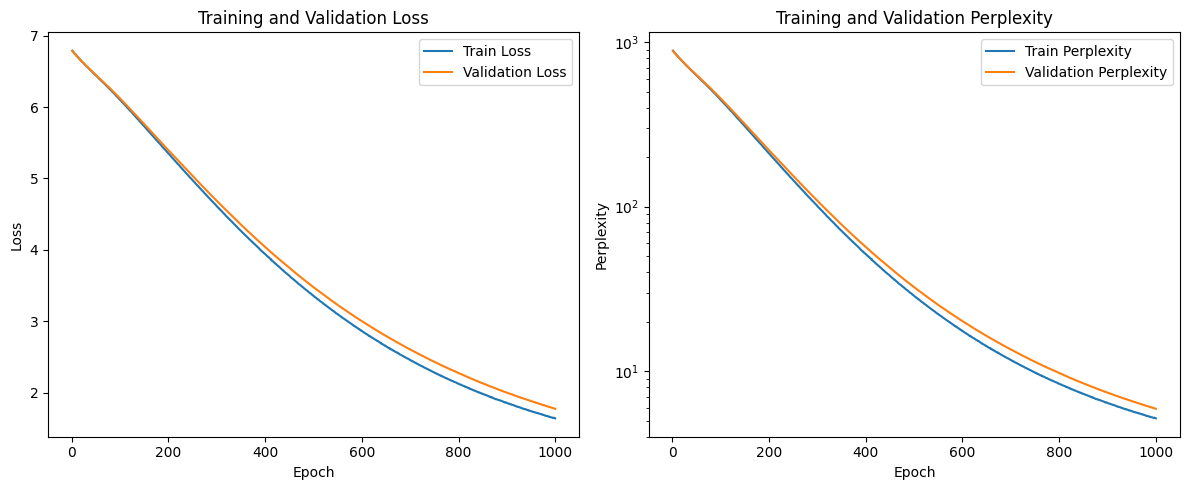

In [39]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
plt.yscale('log')
# plt.grid(True)
plt.tight_layout()
plt.show()


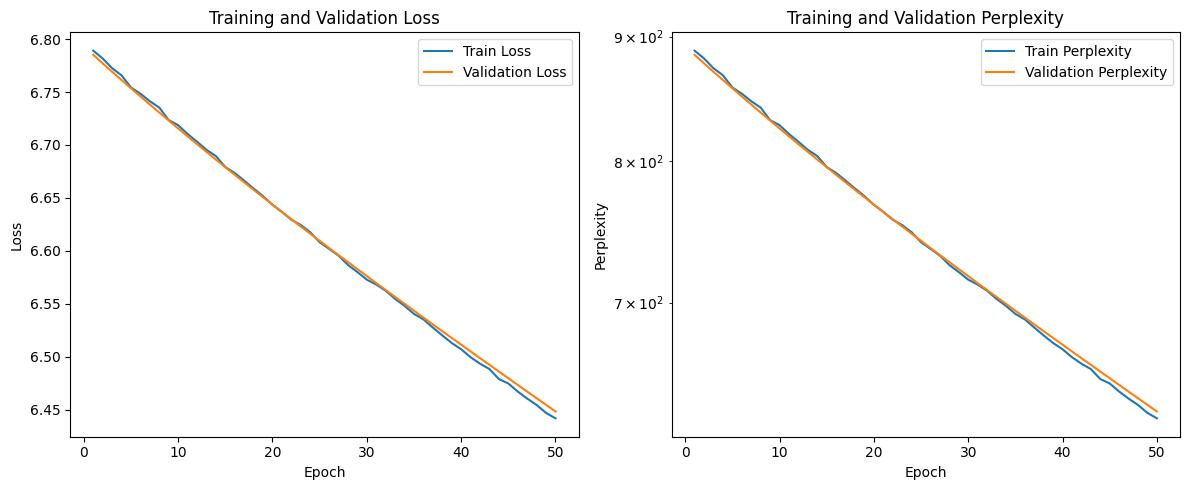

In [40]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]




set_epochs_to_plot = 50
# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(set_epochs_to_plot) + 1), train_losses[:set_epochs_to_plot], label='Train Loss')
plt.plot(range(1, int(set_epochs_to_plot) + 1), val_losses[:set_epochs_to_plot], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(set_epochs_to_plot) + 1), train_perplexities[:set_epochs_to_plot], label='Train Perplexity')
plt.plot(range(1, int(set_epochs_to_plot) + 1), val_perplexities[:set_epochs_to_plot], label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
plt.yscale('log')
# plt.grid(True)
plt.tight_layout()
plt.show()


In [41]:
dfml_metrics = pd.DataFrame()
dfml_metrics['epoch'] = [i+1 for i in range(len(train_losses))]
dfml_metrics['val_loss'] = [val for val in val_losses]
dfml_metrics['train_loss'] = [val for val in train_losses]
dfml_metrics['train_perplexity'] = [val for val in train_perplexities]
dfml_metrics['val_perplexity'] = [val for val in val_perplexities]

In [42]:
dfml_metrics.head()

,epoch,val_loss,train_loss,train_perplexity,val_perplexity
0,1,6.785144,6.789070,888.087598,884.607059
1,2,6.777095,6.781717,881.581015,877.515956
2,3,6.769165,6.772503,873.495639,870.584268
3,4,6.761372,6.765795,867.655380,863.826215
4,5,6.753586,6.754312,857.749525,857.126944


In [43]:
len(train_losses), len(val_losses)

(1000, 1000)

In [44]:
save_ml_metrics = True

In [45]:
if save_ml_metrics:
    dfml_metrics.to_csv(f'{model_tag}_train_metrics.csv', index=False)

### save model

In [46]:
save_model = True

In [47]:
if save_model:
    torch.save(model.state_dict(), f'gpt_model_{model_tag}.pt')

# Vizz Predictions

In [48]:
def show_next_token_prediction(
    model,
    dataloader,
    id_to_token=None,
    device=None,
    top_k=10,           # mostra top-k candidatos do último passo
):
    """
    Mostra a predição do *próximo token* no cenário autoregressivo.
    Considera apenas os logits da última posição válida do prompt.
    """
    if id_to_token is None:
        id_to_token = {}
    if device is None:
        device = next(model.parameters()).device

    # pega um batch e seleciona o primeiro exemplo
    x_batch, y_batch, attn_batch = next(iter(dataloader))
    x = x_batch[0]         # [T]
    y = y_batch[0]         # [T]
    attn = attn_batch[0]   # [T]

    # último índice válido (ignora PAD à direita)
    T_valid = int(attn.sum().item())
    if T_valid < 1:
        print("Exemplo sem tokens válidos.")
        return

    model.eval()
    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(device),
                       attention_mask=attn.unsqueeze(0).to(device))  # [1, T, V]
        last_logits = logits[0, T_valid - 1, :].cpu()                 # [V]
        probs = torch.softmax(last_logits, dim=-1)
        pred_id = int(torch.argmax(probs).item())

    # alvo "gold" para o próximo token (deve existir em y[T_valid-1])
    gold_id = int(y[T_valid - 1].item())
    has_gold = (gold_id != -100)

    # helpers
    def tok2str(tid): return id_to_token.get(int(tid), str(int(tid)))

    prompt_ids = x[:T_valid].tolist()
    prompt_str = [tok2str(t) for t in prompt_ids]
    pred_str = tok2str(pred_id)
    gold_str = tok2str(gold_id) if has_gold else "-"

    # impressão principal
    print("\n=== Próximo token (AR) ===")
    print("Input (x):")
    print("[" + " ".join(prompt_str) + "]\n")
    print("Alvo (próximo token):", gold_str)
    print("Predição (argmax token):", pred_str)
    if has_gold:
        correto = ("SIM" if pred_id == gold_id else "NÃO")
        print("Correto?:", correto)
        print(f"p(gold) = {probs[gold_id].item():.4f} | p(pred) = {probs[pred_id].item():.4f}")

    # top-k candidatos do último passo
    if top_k is not None and top_k > 0:
        k = min(top_k, last_logits.numel())
        vals, idxs = torch.topk(probs, k=k)
        print("\nTop-{} candidatos:".format(k))
        for rank in range(k):
            tid = int(idxs[rank].item())
            print(f"{rank+1:>2}. {tok2str(tid):<12} p={vals[rank].item():.4f}")


In [49]:
show_next_token_prediction(
    model, val_loader,
    top_k=3
)


=== Próximo token (AR) ===
Input (x):
[205 214 213 592 594 603 601 602 605]

Alvo (próximo token): 606
Predição (argmax token): 606
Correto?: SIM
p(gold) = 0.8341 | p(pred) = 0.8341

Top-3 candidatos:
 1. 606          p=0.8341
 2. 598          p=0.0265
 3. 602          p=0.0173


## vizz embedding

In [50]:
with torch.no_grad():
    # matriz de embeddings normalizada [V, D]
    E = F.normalize(model.embedding.weight, dim=1)
    
    # produto interno de todos com todos => coseno (pois já normalizado)
    sim_matrix = E @ E.T   # [V, V]

In [51]:
embedded_data = model.embedding.weight.cpu().detach().numpy()
embedded_data.shape

(773, 16)

In [52]:
save_embedded_data = True

In [53]:
if save_embedded_data:
    embedd_dt = pd.DataFrame(embedded_data)
    embedd_dt.to_csv(f"embedded_repr_gpt_{model_tag}_post_train_.csv",index=False, header=True)

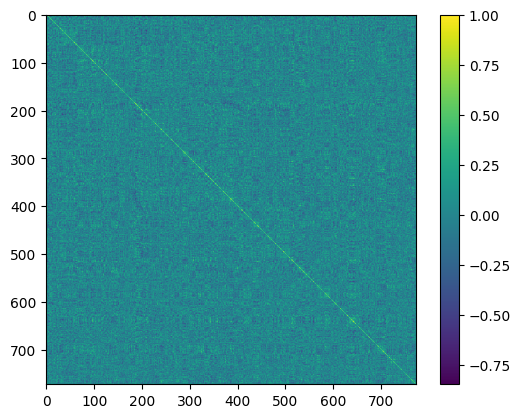

In [55]:
plt.imshow(sim_matrix.cpu().numpy())
plt.colorbar()
plt.show()

In [56]:
save_coss = True

In [57]:
if save_coss:
    coss = pd.DataFrame(sim_matrix.cpu().numpy())
    coss.to_csv(f"cosine_similarity_matrix_gpt_{model_tag}_post_train_.csv",index=False, header=True)

## vizz head projections

## vizz generate

In [58]:
@torch.no_grad()
def next_token_preview(model, dataloader, i: int = 0, top_k: int = 10,
                       id_to_token=None, device=None):
    """
    Mostra só o último passo válido (AR): prompt, alvo e top-k do próximo token.
    Retorna um dicionário com tudo que foi calculado.
    """
    if id_to_token is None: id_to_token = {}
    if device is None: device = next(model.parameters()).device

    x_batch, y_batch, attn_batch = next(iter(dataloader))
    b = i % x_batch.size(0)
    x, y, attn = x_batch[b].to(device), y_batch[b].to(device), attn_batch[b].to(device)

    T_valid = int(attn.sum().item())
    if T_valid < 1:
        print("Exemplo sem tokens válidos."); return {}

    model.eval()
    logits = model(x.unsqueeze(0), attention_mask=attn.unsqueeze(0))  # [1, T, V]
    last_logits = logits[0, T_valid - 1]                              # [V]
    probs = torch.softmax(last_logits, dim=-1)
    pred_id = int(torch.argmax(probs).item())
    gold_id = int(y[T_valid - 1].item())
    has_gold = (gold_id != -100)

    def t2s(t): return id_to_token.get(int(t), str(int(t)))
    prompt_ids = x[:T_valid].tolist()

    k = min(top_k, last_logits.numel()) if top_k and top_k > 0 else 0
    top_ids, top_ps = ([], [])
    if k:
        vals, idxs = torch.topk(probs, k=k)
        top_ids = idxs.tolist(); top_ps = vals.tolist()

    # prints curtos
    print("\n=== Próximo token (AR) ===")
    print("Input:", "[" + " ".join(t2s(t) for t in prompt_ids) + "]")
    print("Alvo:", t2s(gold_id) if has_gold else "-",
          "| Pred:", t2s(pred_id),
          "| Correto?:", "SIM" if has_gold and pred_id == gold_id else "—")
    if has_gold:
        print(f"p(gold)={probs[gold_id].item():.4f}  p(pred)={probs[pred_id].item():.4f}")
    if k:
        print(f"Top-{k}: " + ", ".join(f"{t2s(t)}({p:.3f})" for t, p in zip(top_ids, top_ps)))

    return {
        "prompt_ids": prompt_ids,
        "gold_id": None if not has_gold else gold_id,
        "pred_id": pred_id,
        "topk_ids": top_ids,
        "topk_probs": top_ps,
    }

In [59]:
_ = next_token_preview(model, val_loader, i=0, top_k=3,)


=== Próximo token (AR) ===
Input: [205 214 213 592 594 603 601 602 605]
Alvo: 606 | Pred: 606 | Correto?: SIM
p(gold)=0.8341  p(pred)=0.8341
Top-3: 606(0.834), 598(0.027), 602(0.017)


In [ ]:
tokens, d = model.generate_with_distributions(
    torch.tensor(full_fwd_input),
    max_new_tokens=10,
    temperature=1.0,
    top_k=None,
    return_logits=True,
    return_raw_logits=True,
)
len(tokens), tokens

tensor([ 60,  63,  39,  63, 699, 701, 709, 519, 520, 513, 514,  89, 329, 560,
        758, 632, 192, 195, 191], device='cuda:0')

In [62]:
len(d['probs'])

10

In [67]:
save_probs = True

In [68]:
distribs_probs = pd.DataFrame()
for i in range(len(d['probs'])):
    distribs_probs[f'Passo {i+1:02d}'] = d['probs'][i, :]

In [69]:
distribs_probs.idxmax()

Passo 01    383
Passo 02    385
Passo 03    383
Passo 04    397
Passo 05    401
Passo 06    595
Passo 07    227
Passo 08    226
Passo 09    109
Passo 10     32
dtype: int64

In [70]:
distribs_probs.head(2)

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,8.657203e-07,0.000002,0.000001,1.052861e-06,0.000009,0.000002,0.000005,0.000002,0.000014,0.000004
1,2.127081e-06,0.000006,0.000002,9.526509e-07,0.000001,0.000037,0.000019,0.000056,0.000676,0.000063


In [71]:
if save_probs:
    distribs_probs.to_csv(f'{model_tag}_gpt_probs_distribs_383.csv', index=False)

In [72]:
distribs_logits = pd.DataFrame()
for i in range(len(d['logits'])):
    distribs_logits[f'Passo {i+1:02d}'] = d['logits'][i, :]

In [73]:
if save_probs:
    distribs_logits.to_csv(f'{model_tag}_gpt_logits_distribs_383.csv', index=False)

In [74]:
distribs_logits_raw = pd.DataFrame()
for i in range(len(d['logits_raw'])):
    distribs_logits_raw[f'Passo {i+1:02d}'] = d['logits_raw'][i, :]

In [75]:
if save_probs:
    distribs_logits_raw.to_csv(f'{model_tag}_gpt_logits_raw_distribs_383.csv', index=False)

In [ ]:
# d['logits_raw']

In [ ]:
# pd.DataFrame(d, index=range(len(d)))

In [ ]:
df['position_state_id'].value_counts()[:10]

In [ ]:
# apd.head()

## vizz MLP

In [ ]:
@torch.no_grad()
def capturar_mlp_detalhado(model, seq_ids, layer_idx=0, token_ids=(200, 930)):
    layer = model.encoder.layers[layer_idx]
    seq = torch.tensor([seq_ids], device=model.embedding.weight.device)

    cache = {}

    h1 = layer.linear1.register_forward_hook(
        lambda m, inp, out: cache.update({
            "antes_linear1": inp[0].detach().cpu(),
            "apos_linear1": out.detach().cpu(),
            "apos_relu": torch.relu(out).detach().cpu()
        })
    )

    h2 = layer.linear2.register_forward_hook(
        lambda m, inp, out: cache.update({
            "depois_linear2": out.detach().cpu()
        })
    )

    _ = model(seq)

    h1.remove()
    h2.remove()

    ids = seq[0].detach().cpu()
    pos = {int(t): (ids == t).nonzero(as_tuple=True)[0].tolist() for t in token_ids}

    return {
        t: [
            {
                "pos": p,
                "antes_linear1": cache["antes_linear1"][0, p].numpy(),
                "depois_relu": cache["apos_relu"][0, p].numpy(),
                "depois_linear2": cache["depois_linear2"][0, p].numpy(),
            }
            for p in pos[t]
        ]
        for t in token_ids
    }

## viz all steps

In [ ]:
x

In [ ]:
y

In [76]:
full_fwd_input = [371, 369, 368, 381, 384, 383, 384, 381, 384]
full_fwd = snapshot_transformer_forward(model, full_fwd_input)

In [77]:
save_full_fwd = True

In [78]:
if save_full_fwd:
    with open(f'full_fwd_{model_tag}', 'wb') as fil:
        pickle.dump(full_fwd, fil)

In [79]:
full_fwd['pred_ids']

array([372, 368, 381, 384, 383, 385, 383, 384, 383])

In [81]:
full_fwd['tokens'].reshape(-1, 1)

array([[371],
       [369],
       [368],
       [381],
       [384],
       [383],
       [384],
       [381],
       [384]])

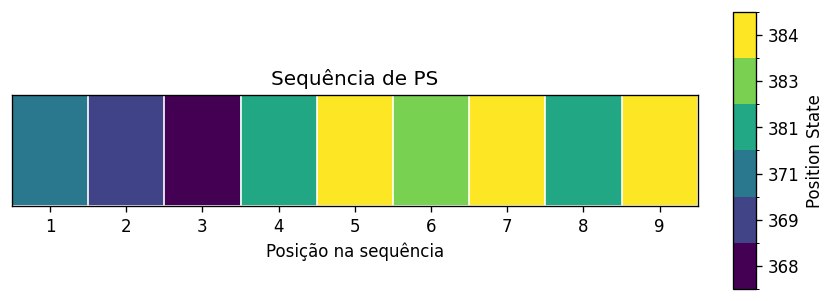

In [82]:
tokens = full_fwd['tokens']
unique_tokens = np.unique(tokens)

# bounds para blocos discretos
bounds = np.append(unique_tokens, unique_tokens[-1] + 1)
norm = mcolors.BoundaryNorm(bounds, ncolors=256)

fig = plt.figure(figsize=(8, 3), dpi=120)
gs = GridSpec(1, 2, width_ratios=[30, 1], wspace=0.1)

# eixo do imshow (mais baixo)
ax = fig.add_subplot(gs[0, 0])

im = ax.imshow(
    tokens.reshape(1, -1),
    cmap='viridis',
    norm=norm,
    aspect='auto'
)

# achatar visualmente o eixo (altura pequena)
pos = ax.get_position()

ax.set_position([pos.x0, pos.y0 + 0.1, pos.width, pos.height * 0.4])

ax.set_yticks([])
ax.set_xlabel("Posição na sequência")
ax.set_title("Sequência de PS")


ax.set_xticks(np.arange(len(tokens)))
ax.set_xticklabels(np.arange(1, len(tokens) + 1))
# colorbar ocupa altura total
cax = fig.add_subplot(gs[0, 1])
cbar = fig.colorbar(im, cax=cax)
# pegar posições atuais
pos_ax = ax.get_position()
pos_cax = cax.get_position()


T = len(tokens)

# linhas verticais separando cada token
ax.set_xticks(np.arange(-0.5, T, 1), minor=True)
ax.grid(which="minor", axis="x", color="white", linewidth=1)

# linha horizontal (opcional, para fechar o bloco)
ax.set_yticks([-0.5, 0.5], minor=True)
ax.grid(which="minor", axis="y", color="white", linewidth=1)

# remover ticks menores visuais
ax.tick_params(which="minor", bottom=False, left=False)



# nova altura do imshow (fração da altura da colorbar)
new_height = pos_cax.height * 0.4

# centralizar verticalmente em relação à colorbar
new_y = pos_cax.y0 + (pos_cax.height - new_height) / 2

# aplicar nova posição
ax.set_position([pos_ax.x0, new_y, pos_ax.width, new_height])
# 🔑 centralizar ticks nas células
tick_positions = (bounds[:-1] + bounds[1:]) / 2
cbar.set_ticks(tick_positions)
cbar.set_ticklabels([str(t) for t in unique_tokens])

cbar.set_label("Position State")

plt.show()

In [83]:
def plot_token_embedding(full_fwd, cmap="viridis"):
    emb = full_fwd["token_embedding"]

    if emb.ndim == 3:
        emb = emb[0]

    emb = np.asarray(emb)     # [T, D]
    mat = emb.T               # [D, T]

    T = mat.shape[1]
    D = mat.shape[0]

    fig = plt.figure(figsize=(6, 6), dpi=120)  # 🔑 mais quadrado
    gs = GridSpec(1, 2, width_ratios=[30, 1], wspace=0.08)

    ax = fig.add_subplot(gs[0, 0])

    im = ax.imshow(
        mat,
        cmap=cmap,
        aspect='equal',   # 🔑 células quadradas
        origin='lower'
    )

    ax.set_title("PS Embedding")
    ax.set_xlabel("Posição na sequência")
    ax.set_ylabel("Dimensão do embedding")

    # ticks principais
    ax.set_xticks(np.arange(T))
    ax.set_xticklabels(np.arange(1, T + 1))

    ax.set_yticks(np.arange(D))
    ax.set_yticklabels(np.arange(1, D + 1))

    # 🔑 GRID DISCRETO (igual ao dos tokens)
    ax.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, D, 1), minor=True)

    ax.grid(which="minor", color="white", linewidth=1)

    ax.tick_params(which="minor", bottom=False, left=False)

    # colorbar
    cax = fig.add_subplot(gs[0, 1])
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label("Valor do embedding")
    # plt.tight_layout()
    plt.show()

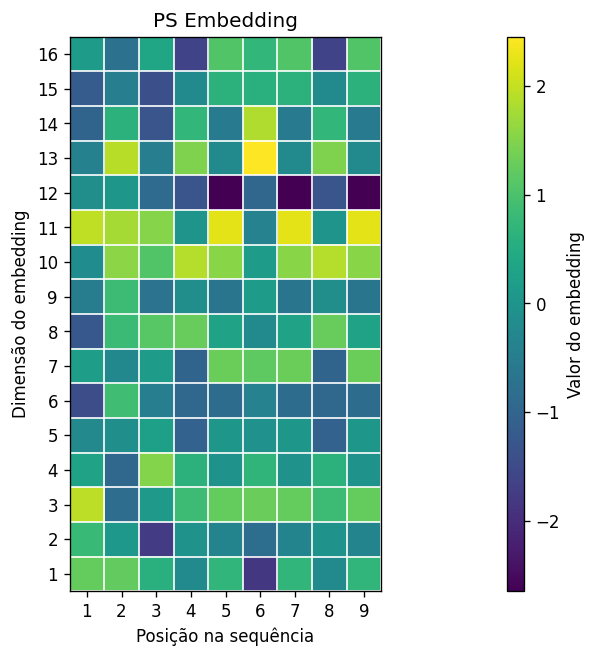

In [84]:
plot_token_embedding(full_fwd, )

In [85]:
def plot_position_embedding(full_fwd, cmap="viridis"):
    pos = full_fwd["position_embedding"]

    if pos.ndim == 3:
        pos = pos[0]

    pos = np.asarray(pos)     # [T, D]
    mat = pos.T               # [D, T]

    T = mat.shape[1]
    D = mat.shape[0]

    fig = plt.figure(figsize=(6, 6), dpi=120)
    gs = GridSpec(1, 2, width_ratios=[30, 1], wspace=0.08)

    ax = fig.add_subplot(gs[0, 0])

    im = ax.imshow(
        mat,
        cmap=cmap,
        aspect='equal',
        origin='lower'   # 🔑 eixo y crescente
    )

    ax.set_title("Positional Embedding")
    ax.set_xlabel("Posição na sequência")
    ax.set_ylabel("Dimensão do embedding")

    # ticks principais
    ax.set_xticks(np.arange(T))
    ax.set_xticklabels(np.arange(1, T + 1))

    ax.set_yticks(np.arange(D))
    ax.set_yticklabels(np.arange(1, D + 1))

    # grid discreto
    ax.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    # colorbar
    cax = fig.add_subplot(gs[0, 1])
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label("Valor do embedding")

    plt.show()

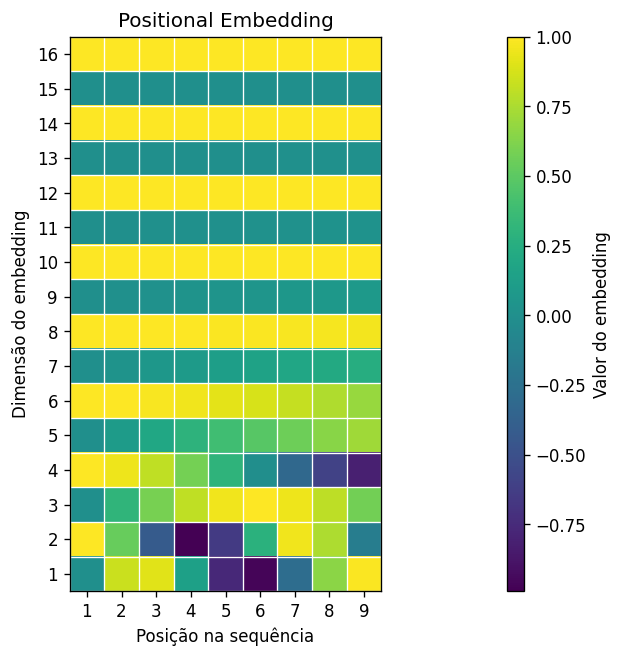

In [86]:
plot_position_embedding(full_fwd)

In [87]:
def plot_embedding_plus_position(full_fwd, cmap="viridis"):
    emb_pos = full_fwd["embedding_plus_position"]

    if emb_pos.ndim == 3:
        emb_pos = emb_pos[0]

    emb_pos = np.asarray(emb_pos)   # [T, D]
    mat = emb_pos.T                 # [D, T]

    T = mat.shape[1]
    D = mat.shape[0]

    fig = plt.figure(figsize=(6, 6), dpi=120)
    gs = GridSpec(1, 2, width_ratios=[30, 1], wspace=0.08)

    ax = fig.add_subplot(gs[0, 0])

    im = ax.imshow(
        mat,
        cmap=cmap,
        aspect="equal",
        origin="lower"
    )

    ax.set_title("Embedding + Pos. Embedding")
    ax.set_xlabel("Posição na sequência")
    ax.set_ylabel("Dimensão do embedding")

    ax.set_xticks(np.arange(T))
    ax.set_xticklabels(np.arange(1, T + 1))

    ax.set_yticks(np.arange(D))
    ax.set_yticklabels(np.arange(1, D + 1))

    ax.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    cax = fig.add_subplot(gs[0, 1])
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label("Valor do embedding")

    plt.show()

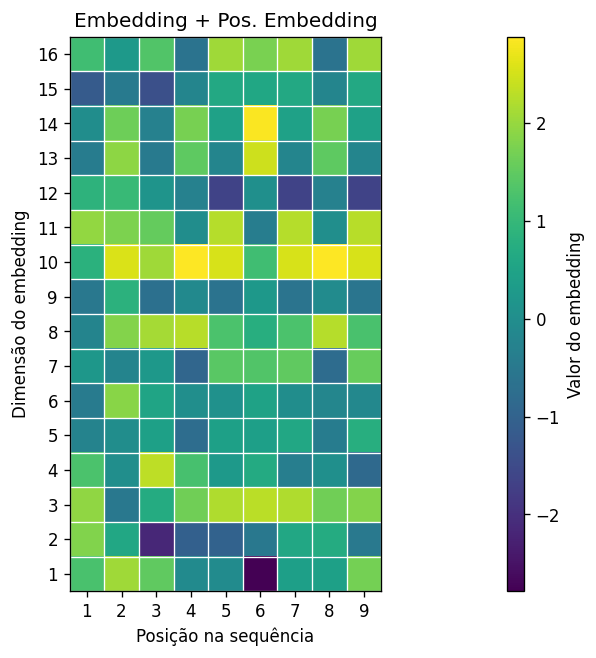

In [88]:
plot_embedding_plus_position(full_fwd)

In [89]:
def plot_query_transformation(full_fwd, cmap="viridis"):
    X = np.asarray(full_fwd["embedding_plus_position"])   # [T, D]
    W = np.asarray(full_fwd["W_q"])                       # [D, D]
    b = np.asarray(full_fwd["b_q"])                       # [D]
    Y = np.asarray(full_fwd["q"])                         # [T, D]

    T, D = X.shape

    all_vals = np.concatenate([X.ravel(), W.ravel(), b.ravel(), Y.ravel()])
    vmin, vmax = all_vals.min(), all_vals.max()

    fig = plt.figure(figsize=(16, 5.4), dpi=120)
    gs = GridSpec(
        1, 5,
        width_ratios=[1.35, 1.9, 0.28, 1.35, 0.08],
        wspace=0.45
    )

    # Embedding + Positional
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        X.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax1.set_title(r"$x$", fontweight='bold')
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D))
    ax1.set_yticklabels(np.arange(1, D + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    # W_q
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        W,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax2.set_title(r"$W_Q$")
    ax2.set_xlabel("Dimensão de Entrada")
    ax2.set_ylabel("Dimensão de Saída")
    ax2.set_xticks(np.arange(D))
    ax2.set_xticklabels(np.arange(1, D + 1))
    ax2.set_yticks(np.arange(D))
    ax2.set_yticklabels(np.arange(1, D + 1))
    ax2.set_xticks(np.arange(-0.5, D, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    # b_q
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        b[:, None],
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax3.set_title(r"$b_Q$")
    ax3.set_xticks([])
    ax3.set_ylabel("Dimensão")
    ax3.set_yticks(np.arange(D))
    ax3.set_yticklabels(np.arange(1, D + 1))
    ax3.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.6)
    ax3.tick_params(which="minor", bottom=False, left=False)

    # Queries
    ax4 = fig.add_subplot(gs[0, 3])
    im4 = ax4.imshow(
        Y.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax4.set_title(r"Consultas ($q$)")
    ax4.set_xlabel("Token")
    ax4.set_ylabel("Dimensão")
    ax4.set_xticks(np.arange(T))
    ax4.set_xticklabels(np.arange(1, T + 1))
    ax4.set_yticks(np.arange(D))
    ax4.set_yticklabels(np.arange(1, D + 1))
    ax4.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax4.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax4.grid(which="minor", color="white", linewidth=0.6)
    ax4.tick_params(which="minor", bottom=False, left=False)

    # única colorbar
    cax = fig.add_subplot(gs[0, 4])
    cbar = fig.colorbar(im4, cax=cax)
    cbar.set_label("Valor")

    fig.suptitle("Transformação para Consultas", fontsize=18)
    plt.show()

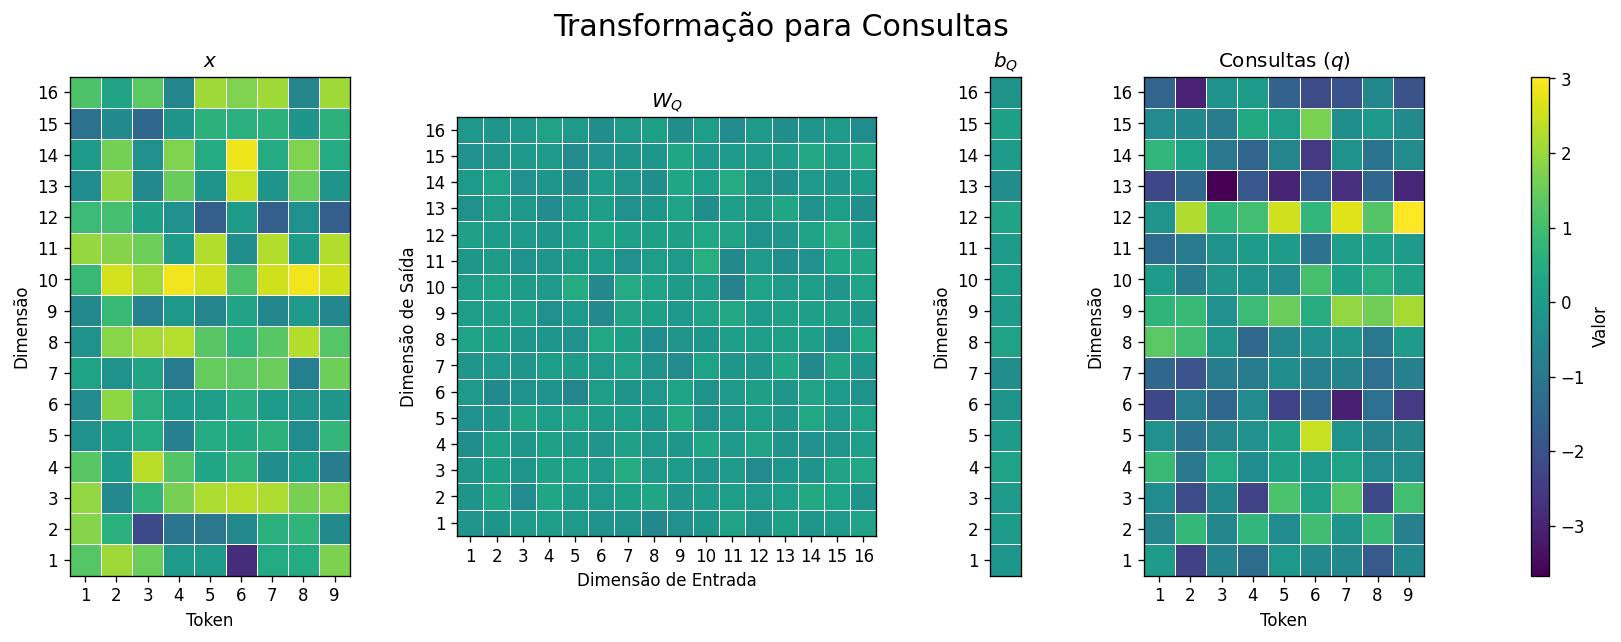

In [90]:
plot_query_transformation(full_fwd)

In [91]:
def plot_key_transformation(full_fwd, cmap="viridis"):
    X = np.asarray(full_fwd["embedding_plus_position"])   # [T, D]
    W = np.asarray(full_fwd["W_k"])                       # [D, D]
    b = np.asarray(full_fwd["b_k"])                       # [D]
    Y = np.asarray(full_fwd["k"])                         # [T, D]

    T, D = X.shape

    all_vals = np.concatenate([X.ravel(), W.ravel(), b.ravel(), Y.ravel()])
    vmin, vmax = all_vals.min(), all_vals.max()

    fig = plt.figure(figsize=(16, 5.4), dpi=120)
    gs = GridSpec(
        1, 5,
        width_ratios=[1.35, 1.9, 0.28, 1.35, 0.08],
        wspace=0.45
    )

    # Embedding + Positional
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        X.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax1.set_title(r"$x$", fontweight='bold')
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D))
    ax1.set_yticklabels(np.arange(1, D + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    # W_k
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        W,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax2.set_title(r"$W_K$")
    ax2.set_xlabel("Dimensão de Entrada")
    ax2.set_ylabel("Dimensão de Saída")
    ax2.set_xticks(np.arange(D))
    ax2.set_xticklabels(np.arange(1, D + 1))
    ax2.set_yticks(np.arange(D))
    ax2.set_yticklabels(np.arange(1, D + 1))
    ax2.set_xticks(np.arange(-0.5, D, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    # b_k
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        b[:, None],
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax3.set_title(r"$b_K$")
    ax3.set_xticks([])
    ax3.set_ylabel("Dimensão")
    ax3.set_yticks(np.arange(D))
    ax3.set_yticklabels(np.arange(1, D + 1))
    ax3.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.6)
    ax3.tick_params(which="minor", bottom=False, left=False)

    # Keys
    ax4 = fig.add_subplot(gs[0, 3])
    im4 = ax4.imshow(
        Y.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax4.set_title(r"Chaves ($k$)")
    ax4.set_xlabel("Token")
    ax4.set_ylabel("Dimensão")
    ax4.set_xticks(np.arange(T))
    ax4.set_xticklabels(np.arange(1, T + 1))
    ax4.set_yticks(np.arange(D))
    ax4.set_yticklabels(np.arange(1, D + 1))
    ax4.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax4.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax4.grid(which="minor", color="white", linewidth=0.6)
    ax4.tick_params(which="minor", bottom=False, left=False)

    # única colorbar
    cax = fig.add_subplot(gs[0, 4])
    cbar = fig.colorbar(im4, cax=cax)
    cbar.set_label("Valor")

    fig.suptitle("Transformação para Chaves", fontsize=18)
    plt.show()

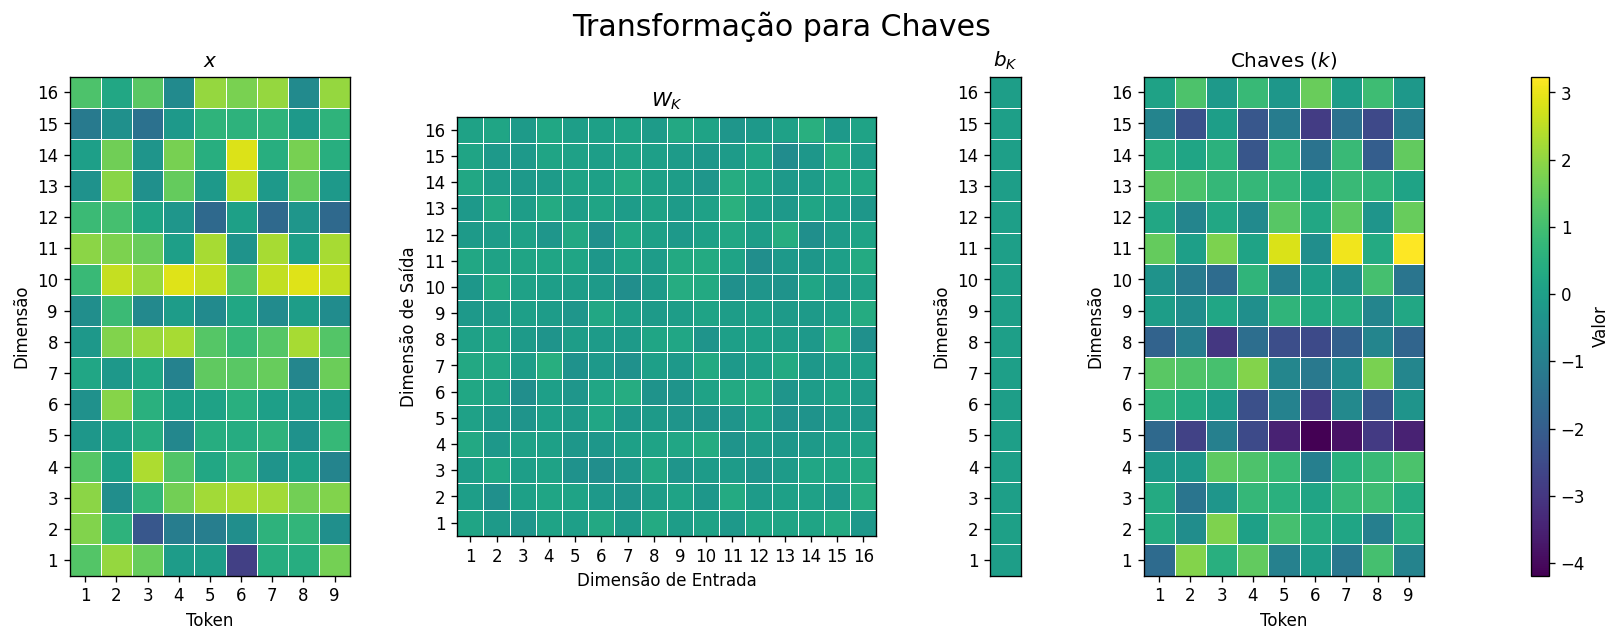

In [92]:
plot_key_transformation(full_fwd)

In [93]:
def plot_value_transformation(full_fwd, cmap="viridis"):
    X = np.asarray(full_fwd["embedding_plus_position"])   # [T, D]
    W = np.asarray(full_fwd["W_v"])                       # [D, D]
    b = np.asarray(full_fwd["b_v"])                       # [D]
    Y = np.asarray(full_fwd["v"])                         # [T, D]

    T, D = X.shape

    all_vals = np.concatenate([X.ravel(), W.ravel(), b.ravel(), Y.ravel()])
    vmin, vmax = all_vals.min(), all_vals.max()

    fig = plt.figure(figsize=(16, 5.4), dpi=120)
    gs = GridSpec(
        1, 5,
        width_ratios=[1.35, 1.9, 0.28, 1.35, 0.08],
        wspace=0.45
    )

    # Embedding + Positional
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        X.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax1.set_title(r"$x$", fontweight='bold')
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D))
    ax1.set_yticklabels(np.arange(1, D + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    # W_v
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        W,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax2.set_title(r"$W_V$")
    ax2.set_xlabel("Dimensão de Entrada")
    ax2.set_ylabel("Dimensão de Saída")
    ax2.set_xticks(np.arange(D))
    ax2.set_xticklabels(np.arange(1, D + 1))
    ax2.set_yticks(np.arange(D))
    ax2.set_yticklabels(np.arange(1, D + 1))
    ax2.set_xticks(np.arange(-0.5, D, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    # b_v
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        b[:, None],
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax3.set_title(r"$b_V$")
    ax3.set_xticks([])
    ax3.set_ylabel("Dimensão")
    ax3.set_yticks(np.arange(D))
    ax3.set_yticklabels(np.arange(1, D + 1))
    ax3.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.6)
    ax3.tick_params(which="minor", bottom=False, left=False)

    # Values
    ax4 = fig.add_subplot(gs[0, 3])
    im4 = ax4.imshow(
        Y.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax4.set_title(r"Valores ($v$)")
    ax4.set_xlabel("Token")
    ax4.set_ylabel("Dimensão")
    ax4.set_xticks(np.arange(T))
    ax4.set_xticklabels(np.arange(1, T + 1))
    ax4.set_yticks(np.arange(D))
    ax4.set_yticklabels(np.arange(1, D + 1))
    ax4.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax4.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax4.grid(which="minor", color="white", linewidth=0.6)
    ax4.tick_params(which="minor", bottom=False, left=False)

    # única colorbar
    cax = fig.add_subplot(gs[0, 4])
    cbar = fig.colorbar(im4, cax=cax)
    cbar.set_label("Valor")

    fig.suptitle("Transformação para Valores", fontsize=18)
    plt.show()

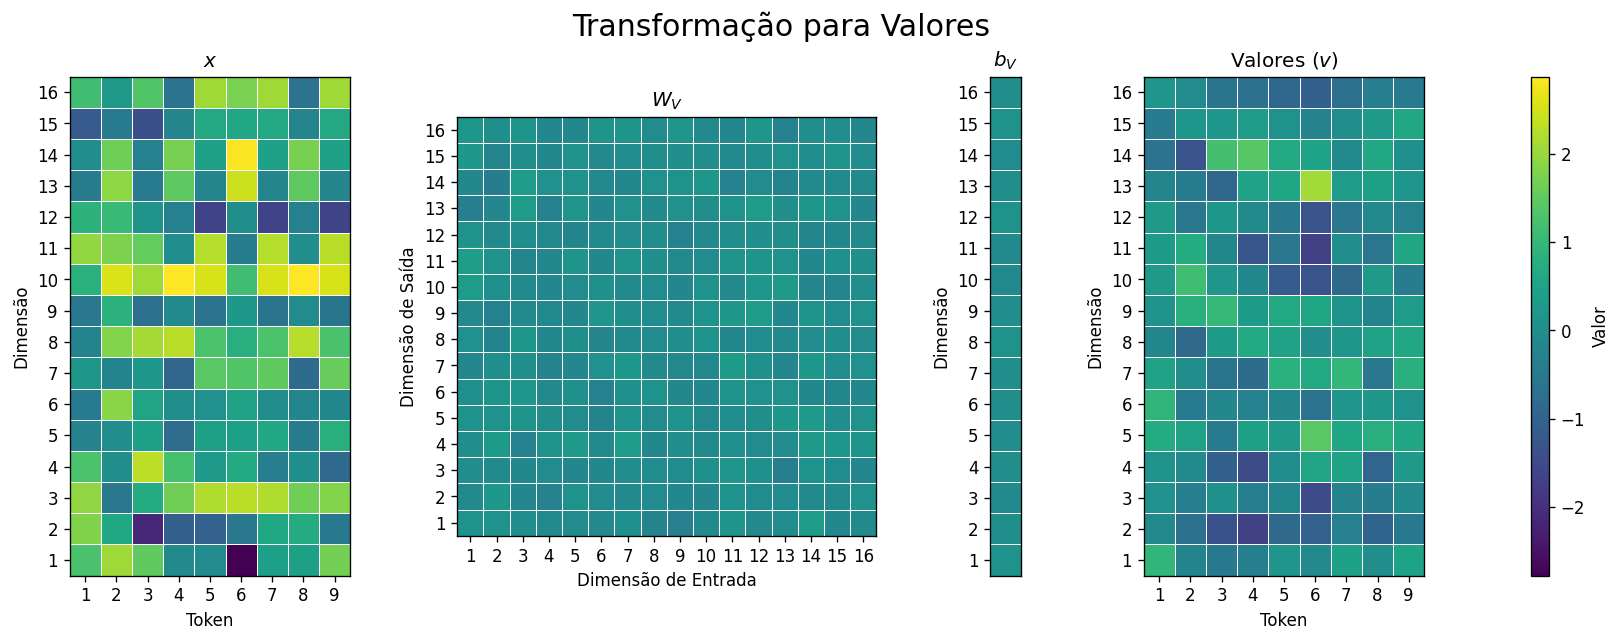

In [94]:
plot_value_transformation(full_fwd)

In [95]:
def plot_similarity_matrix(full_fwd, cmap="viridis"):
    Q = np.asarray(full_fwd["q"])                # [T, D]
    K = np.asarray(full_fwd["k"])                # [T, D]
    S = np.asarray(full_fwd["similarity_raw"])   # [T, T]

    T, D = Q.shape

    # escala global (mesmo padrão das outras funções)
    all_vals = np.concatenate([Q.ravel(), K.ravel(), S.ravel()])
    vmin, vmax = all_vals.min(), all_vals.max()

    fig = plt.figure(figsize=(15, 5.4), dpi=120)
    gs = GridSpec(
        1, 4,
        width_ratios=[1.35, 1.35, 1.45, 0.08],
        wspace=0.45
    )

    # Queries
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        Q.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax1.set_title(r"Consultas ($q$)")
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D))
    ax1.set_yticklabels(np.arange(1, D + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    # Keys
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        K.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax2.set_title(r"Chaves ($k$)")
    ax2.set_xlabel("Token")
    ax2.set_ylabel("Dimensão")
    ax2.set_xticks(np.arange(T))
    ax2.set_xticklabels(np.arange(1, T + 1))
    ax2.set_yticks(np.arange(D))
    ax2.set_yticklabels(np.arange(1, D + 1))
    ax2.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    # Similaridade
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        S,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax3.set_title(r"Similaridade ($S$)")
    ax3.set_xlabel("Token-chave")
    ax3.set_ylabel("Token-consulta")
    ax3.set_xticks(np.arange(T))
    ax3.set_xticklabels(np.arange(1, T + 1))
    ax3.set_yticks(np.arange(T))
    ax3.set_yticklabels(np.arange(1, T + 1))
    ax3.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax3.set_yticks(np.arange(-0.5, T, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.6)
    ax3.tick_params(which="minor", bottom=False, left=False)

    # única colorbar
    cax = fig.add_subplot(gs[0, 3])
    cbar = fig.colorbar(im3, cax=cax)
    cbar.set_label("Valor")

    fig.suptitle("Construção da matriz de similaridade", fontsize=18)
    plt.show()

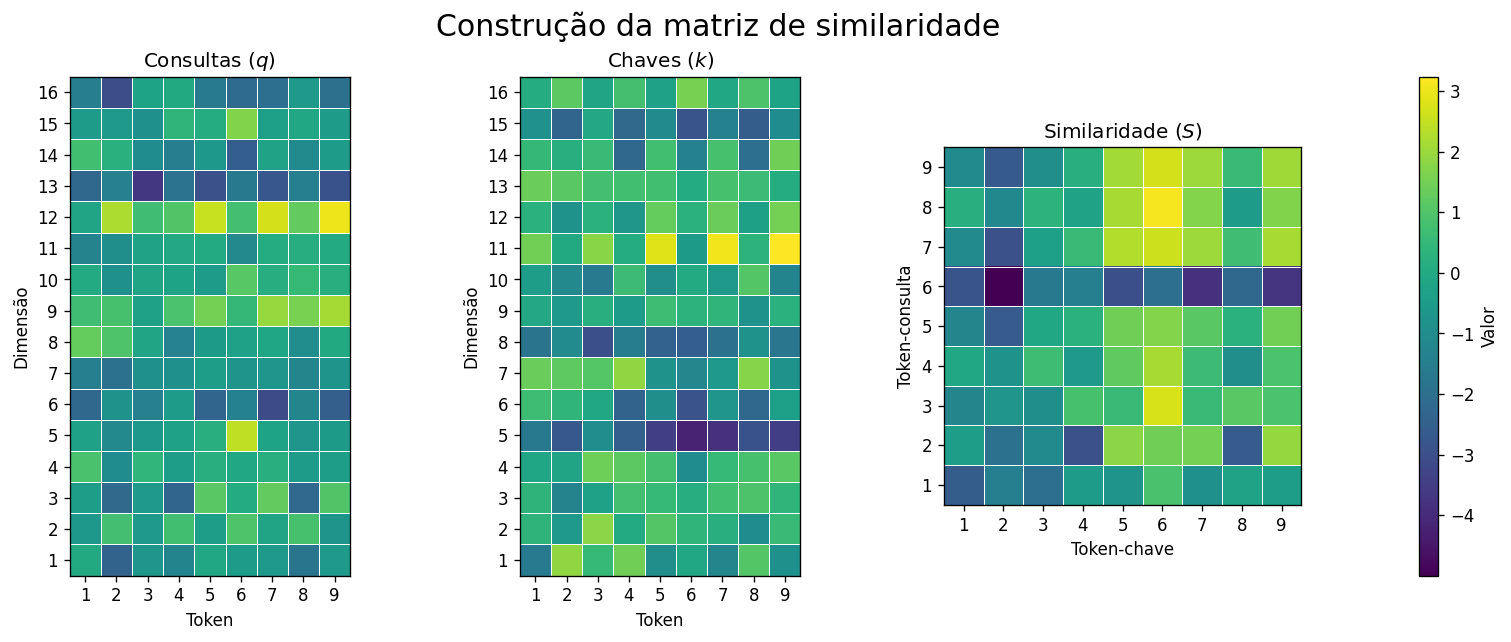

In [96]:
plot_similarity_matrix(full_fwd)

In [97]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
def plot_masked_similarity_and_attention(full_fwd, cmap="viridis"):
    S_masked = np.asarray(full_fwd["similarity_masked"]).copy()
    A = np.asarray(full_fwd["attention_probs"]).copy()

    T = S_masked.shape[0]

    S_plot = S_masked.copy()
    S_plot[np.isneginf(S_plot)] = np.nan

    s_vals = S_plot[np.isfinite(S_plot)]
    vmin_s, vmax_s = s_vals.min(), s_vals.max()

    vmin_a, vmax_a = 0.0, 1.0

    fig = plt.figure(figsize=(12, 6), dpi=120)
    gs = GridSpec(1, 2, width_ratios=[1, 1], wspace=0.45)

    # --- S ---
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        S_plot,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_s,
        vmax=vmax_s
    )
    ax1.set_title(r"$S_{AR}$",fontsize=15)
    ax1.set_xlabel("Token-chave")
    ax1.set_ylabel("Token-consulta")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(T))
    ax1.set_yticklabels(np.arange(1, T + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, T, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="4%", pad=0.08)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Valor de similaridade", labelpad=8)

    # --- A ---
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        A,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_a,
        vmax=vmax_a
    )
    ax2.set_title(r"Pesos de atenção ($A$)", fontsize=15)
    ax2.set_xlabel("Token-chave")
    ax2.set_ylabel("Token-consulta")
    ax2.set_xticks(np.arange(T))
    ax2.set_xticklabels(np.arange(1, T + 1))
    ax2.set_yticks(np.arange(T))
    ax2.set_yticklabels(np.arange(1, T + 1))
    ax2.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, T, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    divider2 = make_axes_locatable(ax2)
    cax2 = divider2.append_axes("right", size="4%", pad=0.08)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Peso de atenção", labelpad=8)

    fig.suptitle(r"Transformação para $S_{AR}$ e $A$", fontsize=18)
    plt.show()

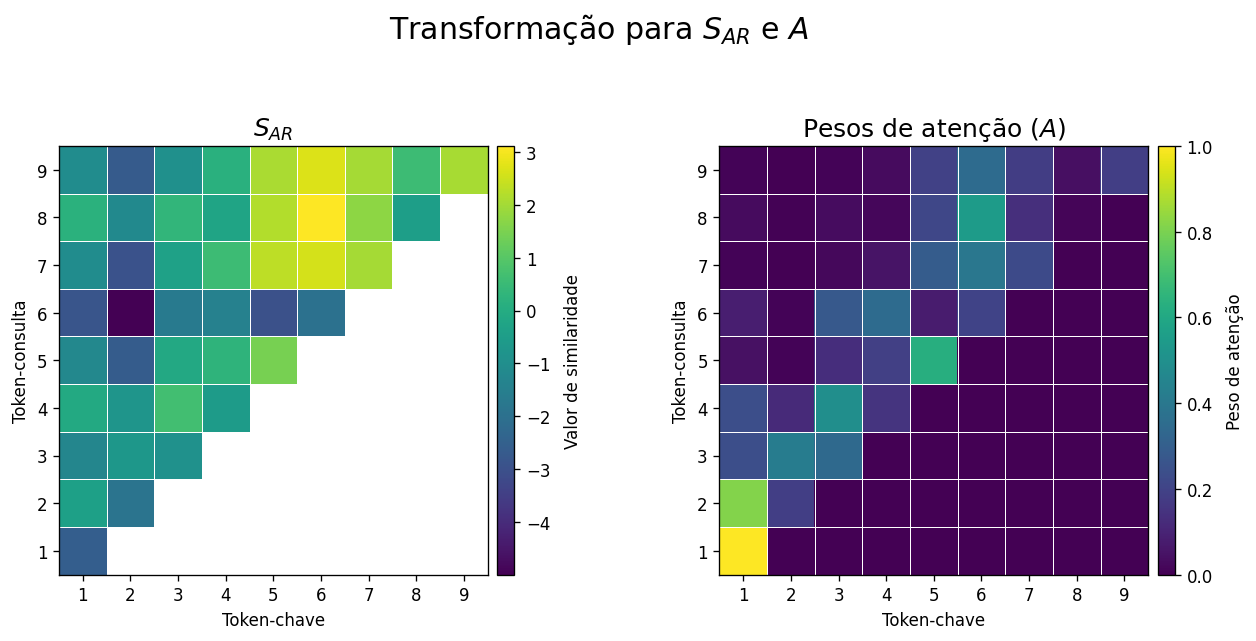

In [98]:
plot_masked_similarity_and_attention(full_fwd)

In [99]:
def plot_attention_value_transformation(full_fwd, cmap="viridis"):
    A = np.asarray(full_fwd["attention_probs"]).copy()              # [T, T]
    V = np.asarray(full_fwd["v"]).copy()                            # [T, D]
    O = np.asarray(full_fwd["attention_weighted_values"]).copy()    # [T, D]

    T, D = V.shape

    vmin_a, vmax_a = 0.0, 1.0
    vmin_v, vmax_v = V.min(), V.max()
    vmin_o, vmax_o = O.min(), O.max()

    fig = plt.figure(figsize=(16, 6), dpi=120)
    gs = GridSpec(1, 3, width_ratios=[1.1, 1.1, 1.1], wspace=0.45)

    # A
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        A,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_a,
        vmax=vmax_a
    )
    ax1.set_title(r"Pesos de atenção ($A$)")
    ax1.set_xlabel("Token-chave")
    ax1.set_ylabel("Token-consulta")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(T))
    ax1.set_yticklabels(np.arange(1, T + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, T, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="4%", pad=0.08)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Peso de atenção", labelpad=8)

    # V
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        V.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_v,
        vmax=vmax_v
    )
    ax2.set_title(r"Valores ($v$)")
    ax2.set_xlabel("Token")
    ax2.set_ylabel("Dimensão")
    ax2.set_xticks(np.arange(T))
    ax2.set_xticklabels(np.arange(1, T + 1))
    ax2.set_yticks(np.arange(D))
    ax2.set_yticklabels(np.arange(1, D + 1))
    ax2.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    divider2 = make_axes_locatable(ax2)
    cax2 = divider2.append_axes("right", size="4%", pad=0.08)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Valor de $v$", labelpad=8)

    # O
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        O.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_o,
        vmax=vmax_o
    )
    ax3.set_title(r"Saída $Y$")
    ax3.set_xlabel("Token")
    ax3.set_ylabel("Dimensão")
    ax3.set_xticks(np.arange(T))
    ax3.set_xticklabels(np.arange(1, T + 1))
    ax3.set_yticks(np.arange(D))
    ax3.set_yticklabels(np.arange(1, D + 1))
    ax3.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax3.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.6)
    ax3.tick_params(which="minor", bottom=False, left=False)

    divider3 = make_axes_locatable(ax3)
    cax3 = divider3.append_axes("right", size="4%", pad=0.08)
    cbar3 = fig.colorbar(im3, cax=cax3)
    cbar3.set_label("Valor da saída", labelpad=8)

    fig.suptitle("Transformação $A\otimes v$", fontsize=18)
    plt.show()

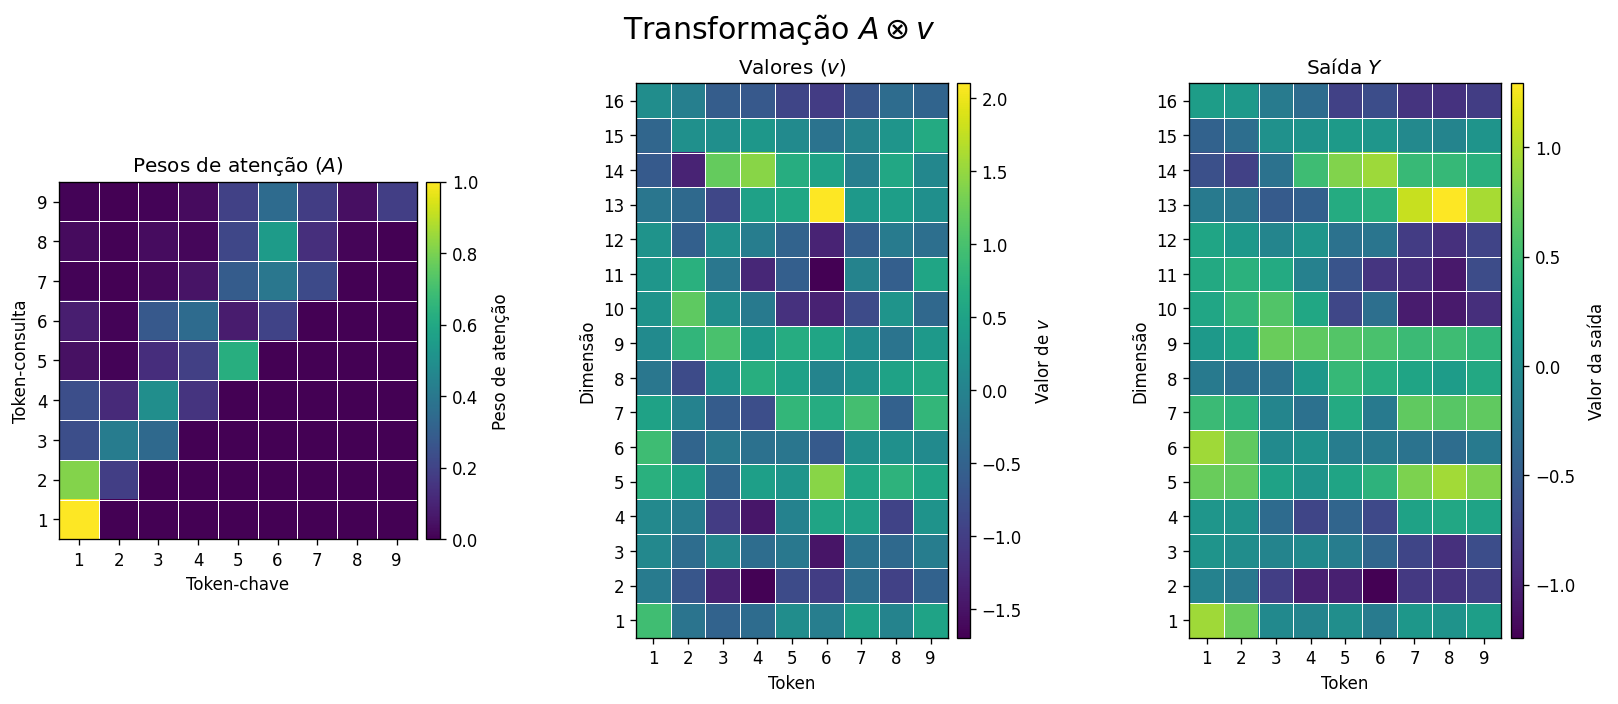

In [100]:
plot_attention_value_transformation(full_fwd)

In [101]:
def plot_linear1_transformation(full_fwd, cmap="viridis"):
    Y = np.asarray(full_fwd["after_attention_block"])   # [T, D]
    W = np.asarray(full_fwd["W_linear1"])               # [D_ff, D]
    b = np.asarray(full_fwd["b_linear1"])               # [D_ff]
    Z = np.asarray(full_fwd["linear1"])                 # [T, D_ff]

    T, D = Y.shape
    D_ff = Z.shape[1]

    vmin_y, vmax_y = Y.min(), Y.max()
    vmin_w, vmax_w = W.min(), W.max()
    vmin_b, vmax_b = vmin_w, vmax_w
    vmin_z, vmax_z = Z.min(), Z.max()

    fig = plt.figure(figsize=(18, 6), dpi=120)
    gs = GridSpec(1, 4, width_ratios=[0.8, 1.9, 0.12, 1.2], wspace=0.45)

    # Y
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        Y.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_y,
        vmax=vmax_y
    )
    ax1.set_title(r"Entrada ($Y$)")
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D))
    ax1.set_yticklabels(np.arange(1, D + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="4%", pad=0.08)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Valor", labelpad=8)

    # W1
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        W,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_w,
        vmax=vmax_w
    )
    ax2.set_title(r"Pesos ($W_1$)")
    ax2.set_xlabel("Dimensão de entrada")
    ax2.set_ylabel("Dimensão de saída")
    ax2.set_xticks(np.arange(D))
    ax2.set_xticklabels(np.arange(1, D + 1))
    ax2.set_yticks(np.arange(D_ff))
    ax2.set_yticklabels(np.arange(1, D_ff + 1))

    
    step = 2

    ax2.set_yticks(np.arange(0, D_ff, step))
    ax2.set_yticklabels(np.arange(1, D_ff + 1, step))

    ax2.set_xticks(np.arange(0, D, step))
    ax2.set_xticklabels(np.arange(1, D + 1, step))


    ax2.set_xticks(np.arange(-0.5, D, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D_ff, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    divider2 = make_axes_locatable(ax2)
    cax2 = divider2.append_axes("right", size="4%", pad=0.08)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Peso / Bias", labelpad=8)

    # b1
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        b[:, None],
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_b,
        vmax=vmax_b
    )
    ax3.set_title(r"Bias ($b_1$)")
    ax3.set_xticks([])
    ax3.set_ylabel("Dimensão")
    ax3.set_yticks(np.arange(D_ff))
    ax3.set_yticklabels(np.arange(1, D_ff + 1,))
    ax3.set_yticks(np.arange(0, D_ff, step))
    ax3.set_yticklabels(np.arange(1, D_ff + 1, step))

    ax3.set_yticks(np.arange(-0.5, D_ff, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.6)
    ax3.tick_params(which="minor", bottom=False, left=False)

    # Z
    ax4 = fig.add_subplot(gs[0, 3])
    im4 = ax4.imshow(
        Z.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_z,
        vmax=vmax_z
    )
    ax4.set_title(r"Saída ($Z$)")
    ax4.set_xlabel("Token")
    ax4.set_ylabel("Dimensão")
    ax4.set_xticks(np.arange(T))
    ax4.set_xticklabels(np.arange(1, T + 1))
    ax4.set_yticks(np.arange(D_ff))
    ax4.set_yticklabels(np.arange(1, D_ff + 1))


    ax4.set_yticks(np.arange(0, D_ff, step))
    ax4.set_yticklabels(np.arange(1, D_ff + 1, step))


    ax4.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax4.set_yticks(np.arange(-0.5, D_ff, 1), minor=True)
    ax4.grid(which="minor", color="white", linewidth=0.6)
    ax4.tick_params(which="minor", bottom=False, left=False)

    divider4 = make_axes_locatable(ax4)
    cax4 = divider4.append_axes("right", size="6%", pad=0.08)
    cbar4 = fig.colorbar(im4, cax=cax4)
    cbar4.set_label("Valor", labelpad=8)

    fig.suptitle("Transformação Linear 1", fontsize=18)
    plt.show()

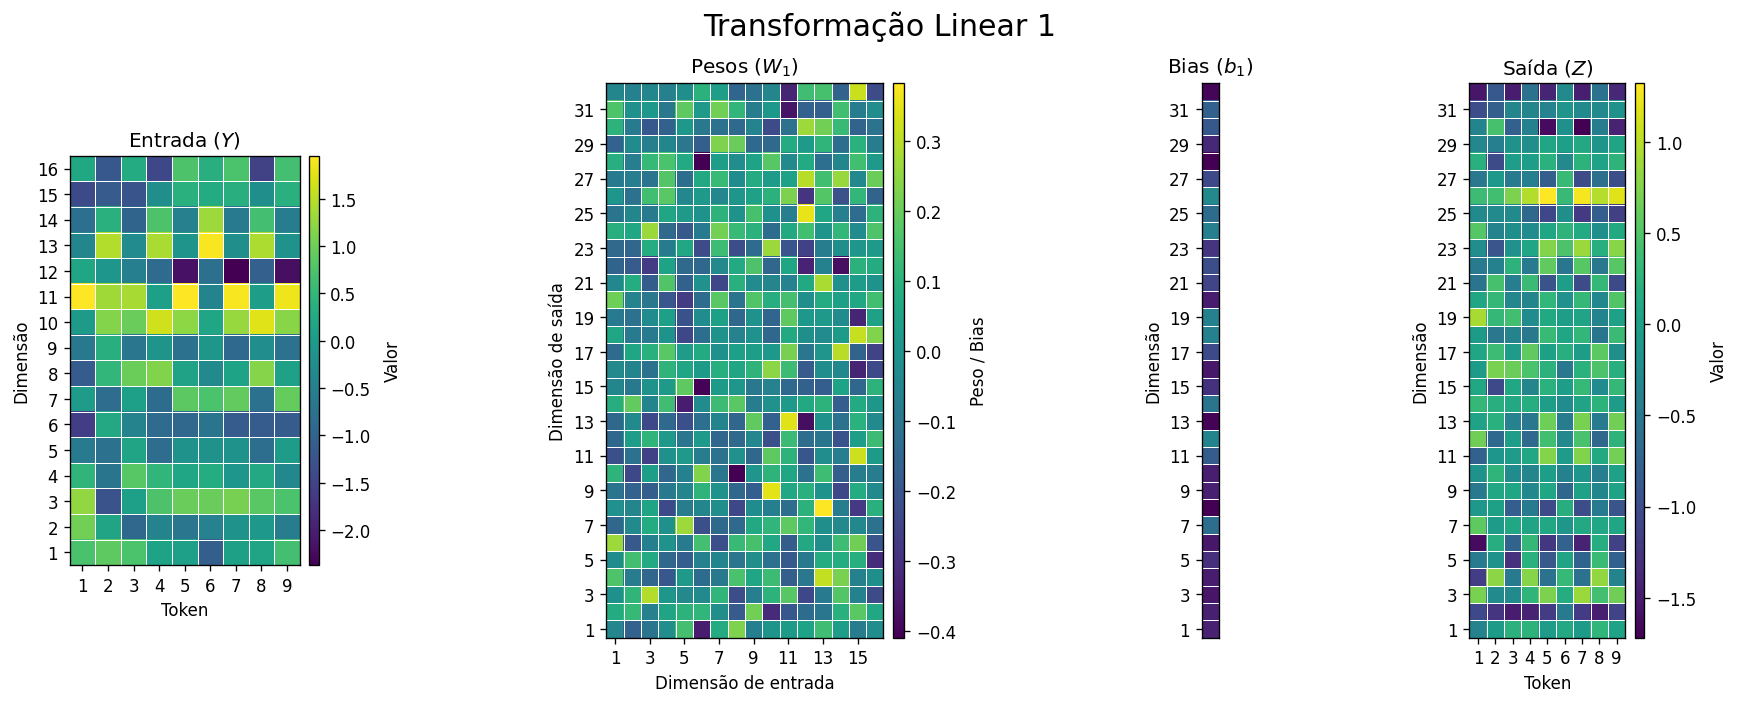

In [102]:
plot_linear1_transformation(full_fwd)

In [103]:
def plot_activation(full_fwd, cmap="viridis"):
    Z = np.asarray(full_fwd["linear1"])     # antes
    A = np.asarray(full_fwd["activation"])  # depois

    T, D = Z.shape

    # mesma escala para comparar corretamente
    vmin = min(Z.min(), A.min())
    vmax = max(Z.max(), A.max())

    fig = plt.figure(figsize=(10, 8), dpi=120)
    gs = GridSpec(1, 3, width_ratios=[1.3, 1.3, 0.08], wspace=0.15)

    # --- antes ---
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        Z.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax1.set_title(r"$Z$")
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D))
    ax1.set_yticklabels(np.arange(1, D + 1))

    
    step = 2

    ax1.set_yticks(np.arange(0, D, step))
    ax1.set_yticklabels(np.arange(1, D + 1, step))

    # grid
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    # --- depois ---
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        A.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax2.set_title(r"ReLU($Z$)")
    ax2.set_xlabel("Token")
    ax2.set_ylabel("Dimensão")
    ax2.set_xticks(np.arange(T))
    ax2.set_xticklabels(np.arange(1, T + 1))
    ax2.set_yticks(np.arange(D))
    ax2.set_yticklabels(np.arange(1, D + 1))

    step = 2

    ax2.set_yticks(np.arange(0, D, step))
    ax2.set_yticklabels(np.arange(1, D + 1, step))


    # grid
    ax2.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    # --- única colorbar ---
    cax = fig.add_subplot(gs[0, 2])
    cbar = fig.colorbar(im2, cax=cax)
    cbar.set_label("Valor")

    fig.suptitle("Transformação ReLU", fontsize=16)
    plt.show()

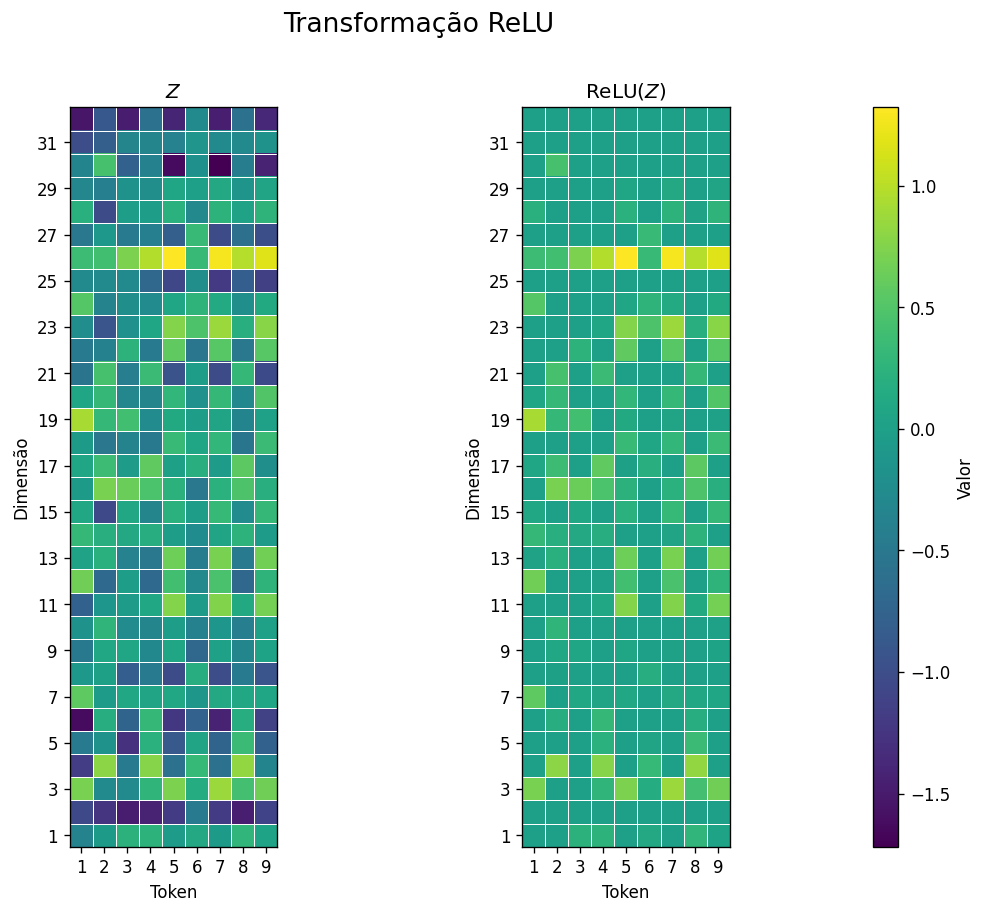

In [104]:
plot_activation(full_fwd)

In [105]:
def plot_linear2_transformation(full_fwd, cmap="viridis"):
    Y = np.asarray(full_fwd["activation"])   # [T, D_ff]
    W = np.asarray(full_fwd["W_linear2"])    # [D, D_ff]
    b = np.asarray(full_fwd["b_linear2"])    # [D]
    Z = np.asarray(full_fwd["linear2"])      # [T, D]

    T, D_ff = Y.shape
    D = Z.shape[1]

    vmin_y, vmax_y = Y.min(), Y.max()
    vmin_w, vmax_w = W.min(), W.max()
    vmin_b, vmax_b = vmin_w, vmax_w
    vmin_z, vmax_z = Z.min(), Z.max()

    fig = plt.figure(figsize=(18, 6), dpi=120)
    gs = GridSpec(1, 4, width_ratios=[1.2, 1.45, 0.22, 1.1], wspace=0.45)

    # Y
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        Y.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_y,
        vmax=vmax_y
    )
    ax1.set_title(r"Entrada ($Z_1$)")
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D_ff))
    ax1.set_yticklabels(np.arange(1, D_ff + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D_ff, 1), minor=True)

    step = 2
    ax1.set_yticks(np.arange(0, D_ff, step))
    ax1.set_yticklabels(np.arange(1, D_ff + 1, step))
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="4%", pad=0.08)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Valor", labelpad=8)

    # W2
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        W,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_w,
        vmax=vmax_w
    )
    ax2.set_title(r"Pesos ($W_2$)")
    ax2.set_xlabel("Dimensão de entrada")
    ax2.set_ylabel("Dimensão de saída")
    ax2.set_xticks(np.arange(D_ff))
    ax2.set_xticklabels(np.arange(1, D_ff + 1))
    ax2.set_yticks(np.arange(D))
    ax2.set_yticklabels(np.arange(1, D + 1))
    ax2.set_xticks(np.arange(-0.5, D_ff, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, D, 1), minor=True)

    step = 2

    ax2.set_xticks(np.arange(0, D_ff, step))
    ax2.set_xticklabels(np.arange(1, D_ff + 1, step))

    ax2.set_yticks(np.arange(0, D, step))
    ax2.set_yticklabels(np.arange(1, D + 1, step))


    ax2.grid(which="minor", color="white", linewidth=0.6)
    ax2.tick_params(which="minor", bottom=False, left=False)

    divider2 = make_axes_locatable(ax2)
    cax2 = divider2.append_axes("right", size="4%", pad=0.08)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Peso / Bias", labelpad=8)

    # b2
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        b[:, None],
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_b,
        vmax=vmax_b
    )
    ax3.set_title(r"Bias ($b_2$)")
    ax3.set_xticks([])
    ax3.set_ylabel("Dimensão")
    ax3.set_yticks(np.arange(D))
    ax3.set_yticklabels(np.arange(1, D + 1))
    ax3.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.6)
    ax3.tick_params(which="minor", bottom=False, left=False)

    # Z
    ax4 = fig.add_subplot(gs[0, 3])
    im4 = ax4.imshow(
        Z.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_z,
        vmax=vmax_z
    )
    ax4.set_title(r"Saída ($Z_2$)")
    ax4.set_xlabel("Token")
    ax4.set_ylabel("Dimensão")
    ax4.set_xticks(np.arange(T))
    ax4.set_xticklabels(np.arange(1, T + 1))
    ax4.set_yticks(np.arange(D))
    ax4.set_yticklabels(np.arange(1, D + 1))
    ax4.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax4.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax4.grid(which="minor", color="white", linewidth=0.6)
    ax4.tick_params(which="minor", bottom=False, left=False)

    divider4 = make_axes_locatable(ax4)
    cax4 = divider4.append_axes("right", size="6%", pad=0.08)
    cbar4 = fig.colorbar(im4, cax=cax4)
    cbar4.set_label("Valor", labelpad=8)

    fig.suptitle("Transformação Linear 2", fontsize=18)
    plt.show()

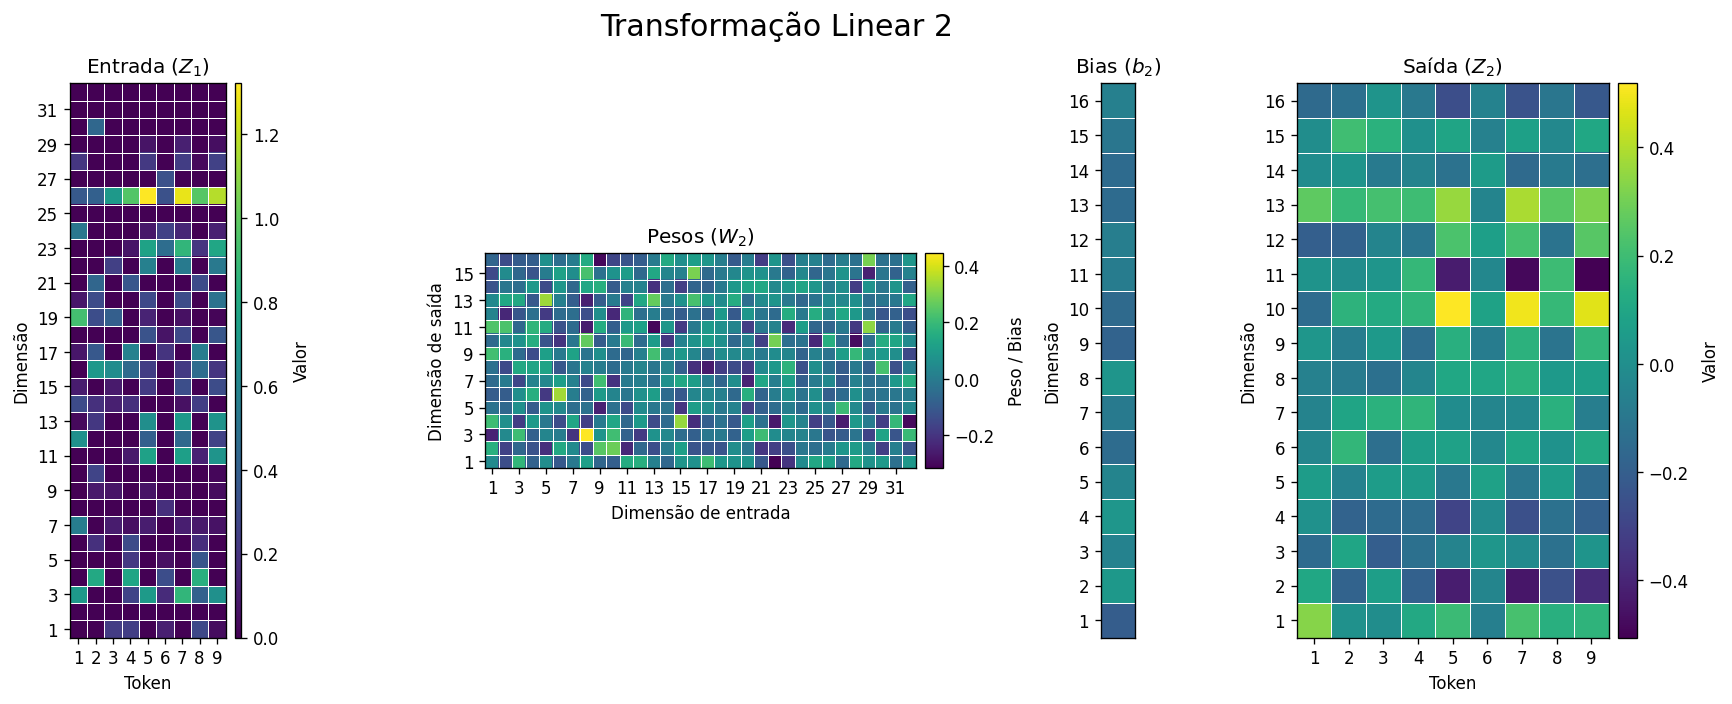

In [106]:
plot_linear2_transformation(full_fwd)

In [107]:
def plot_fc_out_transformation(full_fwd, cmap="viridis"):
    H = np.asarray(full_fwd["after_ffn_block"])   # [T, D]
    W = np.asarray(full_fwd["W_fc_out"])          # [V, D]
    b = np.asarray(full_fwd["b_fc_out"])          # [V]
    Z = np.asarray(full_fwd["logits"])            # [T, V]

    T, D = H.shape
    V = Z.shape[1]

    vmin_h, vmax_h = H.min(), H.max()
    vmin_w, vmax_w = W.min(), W.max()
    vmin_b, vmax_b = vmin_w, vmax_w
    vmin_z, vmax_z = Z.min(), Z.max()

    fig = plt.figure(figsize=(18, 14), dpi=120)
    gs = GridSpec(1, 4, width_ratios=[1.1, 1.45, 0.22, 1.45], wspace=0.45)

    # H
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        H.T,
        cmap=cmap,
        aspect="equal",
        origin="lower",
        vmin=vmin_h,
        vmax=vmax_h
    )
    ax1.set_title(r"Entrada ($H$)")
    ax1.set_xlabel("Token")
    ax1.set_ylabel("Dimensão")
    ax1.set_xticks(np.arange(T))
    ax1.set_xticklabels(np.arange(1, T + 1))
    ax1.set_yticks(np.arange(D))
    ax1.set_yticklabels(np.arange(1, D + 1))
    ax1.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, D, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.6)
    ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="4%", pad=0.08)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Valor", labelpad=8)

    # W_out
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        W,
        cmap=cmap,
        aspect=0.01,
        origin="lower",
        vmin=vmin_w,
        vmax=vmax_w
    )
    ax2.set_title(r"Pesos ($W_{out}$)")
    ax2.set_xlabel("Dimensão de entrada")
    ax2.set_ylabel("Logit de saída")

    step_x = 2 # if D > 20 else 1
    step_y = 100 #max(1, V // 20)

    ax2.set_xticks(np.arange(0, D, step_x))
    ax2.set_xticklabels(np.arange(1, D + 1, step_x))
    ax2.set_yticks(np.arange(0, V, step_y))
    ax2.set_yticklabels(np.arange(1, V + 1, step_y))

    ax2.set_xticks(np.arange(-0.5, D, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, V, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.1)
    ax2.tick_params(which="minor", bottom=False, left=False)

    divider2 = make_axes_locatable(ax2)
    cax2 = divider2.append_axes("right", size="4%", pad=0.08)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Peso / Bias", labelpad=8)

    # b_out
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        b[:, None],
        cmap=cmap,
        aspect="auto",
        origin="lower",
        vmin=vmin_b,
        vmax=vmax_b
    )
    ax3.set_title(r"Bias ($b_{out}$)")
    ax3.set_xticks([])
    ax3.set_ylabel("Logit de saída")
    ax3.set_yticks(np.arange(0, V, step_y))
    ax3.set_yticklabels(np.arange(1, V + 1, step_y))
    ax3.set_yticks(np.arange(-0.5, V, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.1)
    ax3.tick_params(which="minor", bottom=False, left=False)

    # logits
    ax4 = fig.add_subplot(gs[0, 3])
    im4 = ax4.imshow(
        Z.T,
        cmap=cmap,
        aspect="auto",
        origin="lower",
        vmin=vmin_z,
        vmax=vmax_z
    )
    ax4.set_title(r"Saída (logits)")
    ax4.set_xlabel("Token")
    ax4.set_ylabel("Logit de saída")
    ax4.set_xticks(np.arange(T))
    ax4.set_xticklabels(np.arange(1, T + 1))
    ax4.set_yticks(np.arange(0, V, step_y))
    ax4.set_yticklabels(np.arange(1, V + 1, step_y))
    ax4.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax4.set_yticks(np.arange(-0.5, V, 1), minor=True)
    ax4.grid(which="minor", color="white", linewidth=0.1)
    ax4.tick_params(which="minor", bottom=False, left=False)

    divider4 = make_axes_locatable(ax4)
    cax4 = divider4.append_axes("right", size="6%", pad=0.08)
    cbar4 = fig.colorbar(im4, cax=cax4)
    cbar4.set_label("Valor", labelpad=8)

    fig.suptitle("Transformação final pela camada de saída (fc_out)", fontsize=18)
    plt.show()

In [108]:
# plot_fc_out_transformation(full_fwd)

In [109]:
def plot_fc_out_large(full_fwd, cmap="viridis"):
    W = np.asarray(full_fwd["W_fc_out"])   # [V, D]
    b = np.asarray(full_fwd["b_fc_out"])   # [V]
    Z = np.asarray(full_fwd["logits"])     # [T, V]

    V, D = W.shape
    T = Z.shape[0]

    vmin_w, vmax_w = W.min(), W.max()
    vmin_b, vmax_b = vmin_w, vmax_w
    vmin_z, vmax_z = Z.min(), Z.max()

    fig = plt.figure(figsize=(16, 10), dpi=120)
    gs = GridSpec(1, 3, width_ratios=[1.6, 0.4, 1.6], wspace=0.4)

    step_y = 100
    step_x = 2

    # --- W_out ---
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        W,
        cmap=cmap,
        aspect='auto',
        origin="lower",
        vmin=vmin_w,
        vmax=vmax_w
    )
    ax1.set_title(r"Pesos ($W_{out}$)")
    ax1.set_xlabel("Dimensão de entrada")
    ax1.set_ylabel("Logit")

    ax1.set_xticks(np.arange(0, D, step_x))
    ax1.set_xticklabels(np.arange(1, D + 1, step_x))
    ax1.set_yticks(np.arange(0, V, step_y))
    ax1.set_yticklabels(np.arange(1, V + 1, step_y))

    ax1.set_xticks(np.arange(-0.5, D, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, V, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.15)
    ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="3%", pad=0.05)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Peso")

    # --- bias ---
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        b[:, None],
        cmap=cmap,
        aspect='auto',
        origin="lower",
        vmin=vmin_b,
        vmax=vmax_b
    )
    ax2.set_title(r"Bias ($b_{out}$)")
    ax2.set_xticks([])
    ax2.set_ylabel("Logit")

    ax2.set_yticks(np.arange(0, V, step_y))
    ax2.set_yticklabels(np.arange(1, V + 1, step_y))

    ax2.set_yticks(np.arange(-0.5, V, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.15)
    ax2.tick_params(which="minor", bottom=False, left=False)

    # --- logits ---
    ax3 = fig.add_subplot(gs[0, 2])
    im3 = ax3.imshow(
        Z.T,
        cmap=cmap,
        aspect='auto',
        origin="lower",
        vmin=vmin_z,
        vmax=vmax_z
    )
    ax3.set_title("Logits")
    ax3.set_xlabel("Token")
    ax3.set_ylabel("Logit")

    ax3.set_xticks(np.arange(T))
    ax3.set_xticklabels(np.arange(1, T + 1))
    ax3.set_yticks(np.arange(0, V, step_y))
    ax3.set_yticklabels(np.arange(1, V + 1, step_y))

    ax3.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax3.set_yticks(np.arange(-0.5, V, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.15)
    ax3.tick_params(which="minor", bottom=False, left=False)

    divider3 = make_axes_locatable(ax3)
    cax3 = divider3.append_axes("right", size="3%", pad=0.05)
    cbar3 = fig.colorbar(im3, cax=cax3)
    cbar3.set_label("Valor")

    fig.suptitle("Camada de saída (fc_out) — visão detalhada", fontsize=18)
    plt.show()

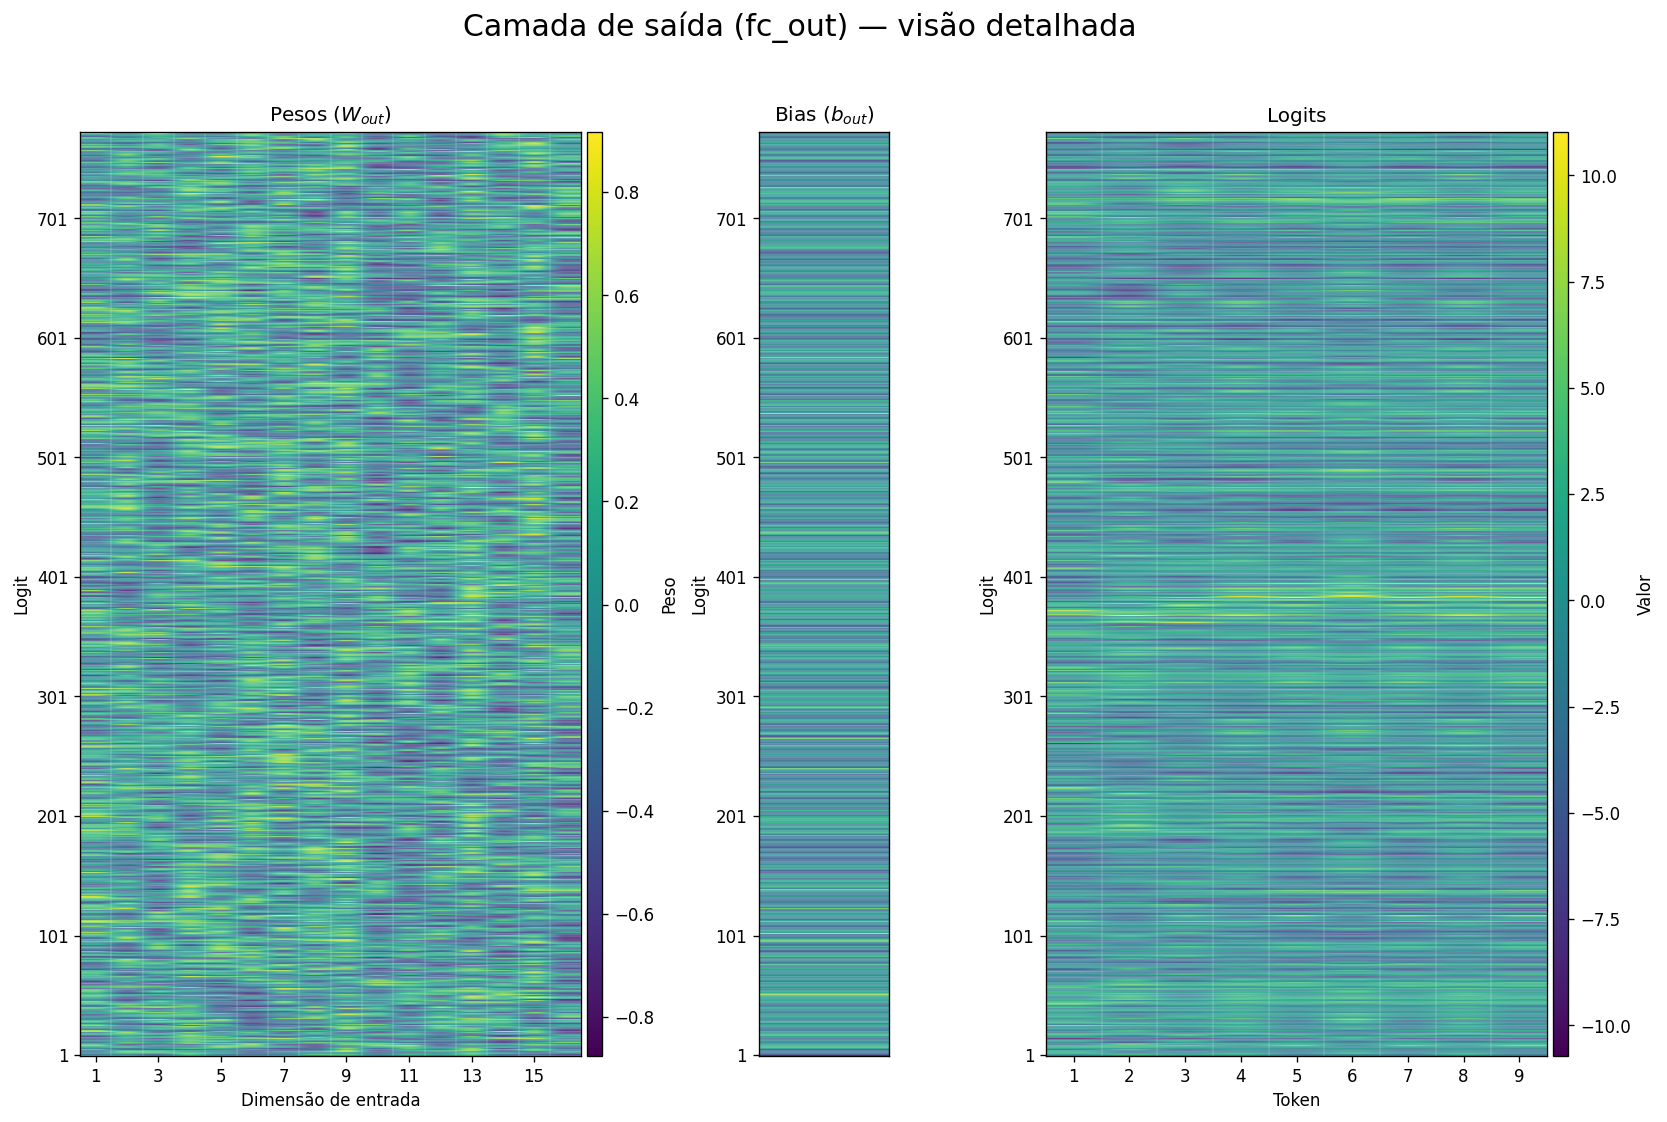

In [110]:
plot_fc_out_large(full_fwd)

In [111]:
def plot_fc_out_large_horizontal(full_fwd, cmap="viridis"):
    W = np.asarray(full_fwd["W_fc_out"])   # [V, D]
    b = np.asarray(full_fwd["b_fc_out"])   # [V]
    Z = np.asarray(full_fwd["logits"])     # [T, V]

    V, D = W.shape
    T = Z.shape[0]

    vmin_w, vmax_w = W.min(), W.max()
    vmin_b, vmax_b = vmin_w, vmax_w
    vmin_z, vmax_z = Z.min(), Z.max()

    fig = plt.figure(figsize=(16, 8), dpi=120)
    gs = GridSpec(3, 1, height_ratios=[1.3, 0.22, 1.3], hspace=0.45)

    step_v = 100
    step_d = 2

    # --- W_out ---
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        W,
        cmap=cmap,
        aspect='auto',
        origin="lower",
        vmin=vmin_w,
        vmax=vmax_w
    )
    ax1.set_title(r"Pesos ($W_{out}$)")
    ax1.set_xlabel("Dimensão de entrada")
    ax1.set_ylabel("Logit de saída")

    ax1.set_xticks(np.arange(0, D, step_d))
    ax1.set_xticklabels(np.arange(1, D + 1, step_d))
    ax1.set_yticks(np.arange(0, V, step_v))
    ax1.set_yticklabels(np.arange(1, V + 1, step_v))

    ax1.set_xticks(np.arange(-0.5, D, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, V, 1), minor=True)
    # ax1.grid(which="minor", color="white", linewidth=0.15)
    # ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="2.5%", pad=0.06)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Peso", labelpad=8)

    # --- b_out ---
    ax2 = fig.add_subplot(gs[1, 0])
    im2 = ax2.imshow(
        b[None, :],
        cmap=cmap,
        aspect="auto",
        origin="lower",
        vmin=vmin_b,
        vmax=vmax_b
    )
    ax2.set_title(r"Bias ($b_{out}$)")
    ax2.set_xlabel("Logit de saída")
    ax2.set_yticks([])

    ax2.set_xticks(np.arange(0, V, step_v))
    ax2.set_xticklabels(np.arange(1, V + 1, step_v))

    ax2.set_xticks(np.arange(-0.5, V, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.15)
    ax2.tick_params(which="minor", bottom=False, left=False)

    divider2 = make_axes_locatable(ax2)
    cax2 = divider2.append_axes("right", size="2.5%", pad=0.06)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Bias", labelpad=8)

    # --- logits ---
    ax3 = fig.add_subplot(gs[2, 0])
    im3 = ax3.imshow(
        Z,
        cmap=cmap,
        aspect='auto',
        origin="lower",
        vmin=vmin_z,
        vmax=vmax_z
    )
    ax3.set_title("Logits")
    ax3.set_xlabel("Logit de saída")
    ax3.set_ylabel("Token")

    ax3.set_xticks(np.arange(0, V, step_v))
    ax3.set_xticklabels(np.arange(1, V + 1, step_v))
    ax3.set_yticks(np.arange(T))
    ax3.set_yticklabels(np.arange(1, T + 1))

    ax3.set_xticks(np.arange(-0.5, V, 1), minor=True)
    ax3.set_yticks(np.arange(-0.5, T, 1), minor=True)
    ax3.grid(which="minor", color="white", linewidth=0.15)
    ax3.tick_params(which="minor", bottom=False, left=False)

    divider3 = make_axes_locatable(ax3)
    cax3 = divider3.append_axes("right", size="2.5%", pad=0.06)
    cbar3 = fig.colorbar(im3, cax=cax3)
    cbar3.set_label("Valor", labelpad=8)

    fig.suptitle("Camada de saída (fc_out) — visão horizontal", fontsize=18)
    plt.show()

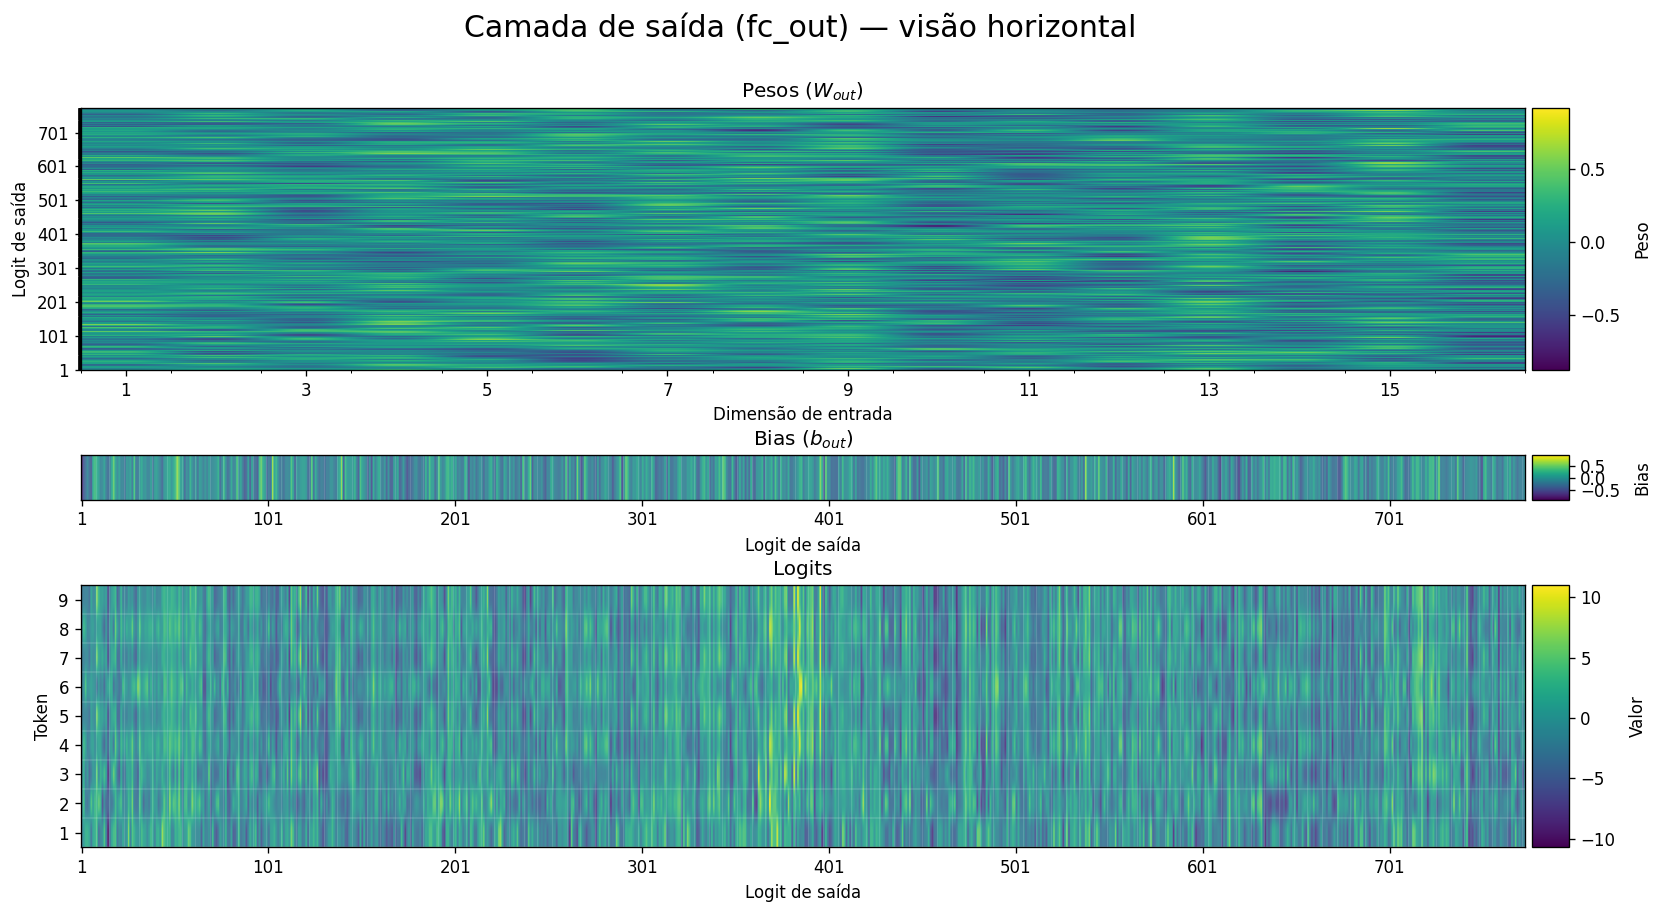

In [112]:
plot_fc_out_large_horizontal(full_fwd)

In [113]:
def plot_softmax(full_fwd, cmap="viridis"):
    logits = np.asarray(full_fwd["logits"])   # [T, V]

    # softmax estável
    logits_shifted = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(logits_shifted)
    probs = exp / exp.sum(axis=1, keepdims=True)

    T, V = probs.shape

    fig = plt.figure(figsize=(14, 6), dpi=120)
    gs = GridSpec(2, 1, height_ratios=[1, 1], hspace=0.4)

    step_v = 100

    # --- logits ---
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        logits,
        cmap=cmap,
        aspect='auto',
        origin="lower"
    )
    ax1.set_title("Logits")
    ax1.set_xlabel("Logit (vocab)")
    ax1.set_ylabel("Token")

    ax1.set_xticks(np.arange(0, V, step_v))
    ax1.set_xticklabels(np.arange(1, V + 1, step_v))
    ax1.set_yticks(np.arange(T))
    ax1.set_yticklabels(np.arange(1, T + 1))

    ax1.set_xticks(np.arange(-0.5, V, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, T, 1), minor=True)
    ax1.grid(which="minor", color="white", linewidth=0.1)
    ax1.tick_params(which="minor", bottom=False, left=False)

    divider1 = make_axes_locatable(ax1)
    cax1 = divider1.append_axes("right", size="2.5%", pad=0.05)
    cbar1 = fig.colorbar(im1, cax=cax1)
    cbar1.set_label("Logit")

    # --- softmax ---
    ax2 = fig.add_subplot(gs[1, 0])
    im2 = ax2.imshow(
        probs,
        cmap=cmap,
        aspect='auto',
        origin="lower",
        vmin=0,
        vmax=1
    )
    ax2.set_title("Softmax (Probabilidades)")
    ax2.set_xlabel("Token (vocab)")
    ax2.set_ylabel("Token")

    ax2.set_xticks(np.arange(0, V, step_v))
    ax2.set_xticklabels(np.arange(1, V + 1, step_v))
    ax2.set_yticks(np.arange(T))
    ax2.set_yticklabels(np.arange(1, T + 1))

    ax2.set_xticks(np.arange(-0.5, V, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, T, 1), minor=True)
    ax2.grid(which="minor", color="white", linewidth=0.1)
    ax2.tick_params(which="minor", bottom=False, left=False)

    divider2 = make_axes_locatable(ax2)
    cax2 = divider2.append_axes("right", size="2.5%", pad=0.05)
    cbar2 = fig.colorbar(im2, cax=cax2)
    cbar2.set_label("Probabilidade")

    fig.suptitle("Transformação Softmax dos Logits", fontsize=16)
    plt.show()

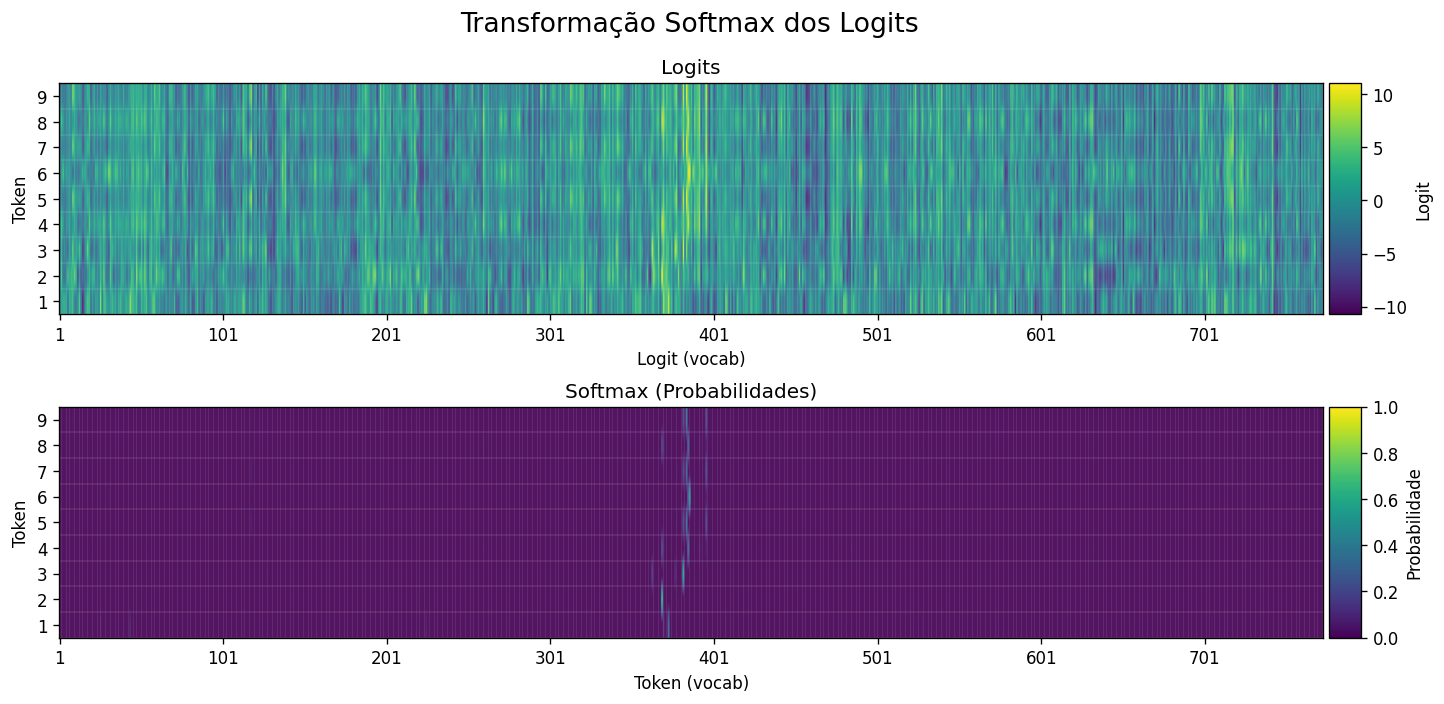

In [114]:
plot_softmax(full_fwd)

In [115]:
def plot_tokens_vs_predictions(full_fwd, cmap="viridis"):
    tokens = np.asarray(full_fwd["tokens"])
    preds = np.asarray(full_fwd["pred_ids"])

    T = len(tokens)

    data = np.vstack([tokens, preds]).astype(float)

    # valores únicos para colorbar discreta
    unique_vals = np.unique(data)
    bounds = np.append(unique_vals, unique_vals[-1] + 1)
    norm = mcolors.BoundaryNorm(bounds, ncolors=256)

    fig = plt.figure(figsize=(14, 3), dpi=120)
    gs = GridSpec(1, 2, width_ratios=[40, 1], wspace=0.1)

    ax = fig.add_subplot(gs[0, 0])
    im = ax.imshow(
        data,
        cmap=cmap,
        norm=norm,
        aspect="auto"
    )

    ax.set_title("Entrada vs Predição (mesma posição)")
    ax.set_xlabel("Posição na sequência")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Tokens", "Predições"])

    ax.set_xticks(np.arange(T))
    ax.set_xticklabels(np.arange(1, T + 1))

    # grid (visual discreto)
    ax.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # colorbar única
    cax = fig.add_subplot(gs[0, 1])
    cbar = fig.colorbar(im, cax=cax)

    tick_positions = (bounds[:-1] + bounds[1:]) / 2
    cbar.set_ticks(tick_positions)
    cbar.set_ticklabels([str(int(v)) for v in unique_vals])
    cbar.set_label("Position State")

    plt.show()

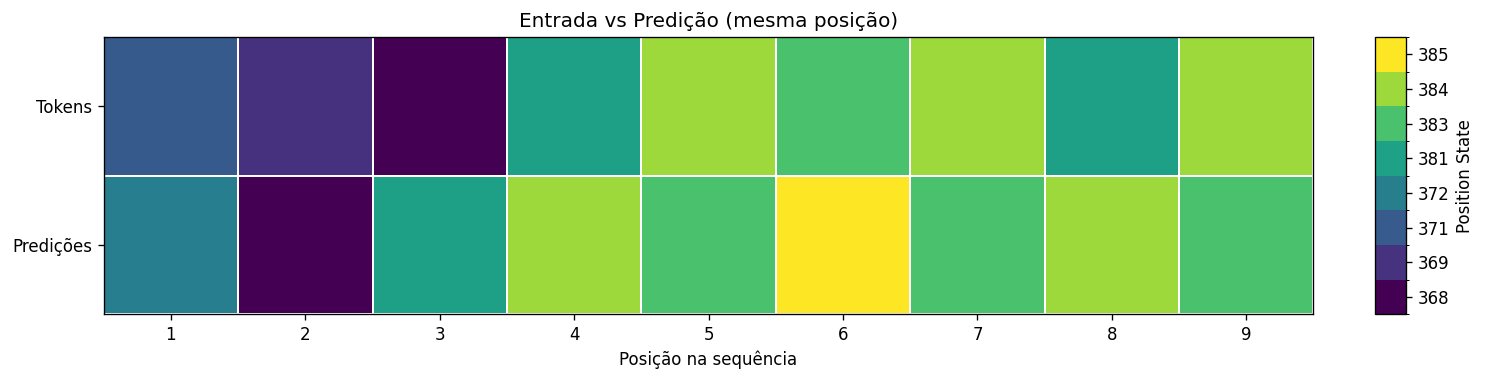

In [116]:
plot_tokens_vs_predictions(full_fwd)

In [117]:
def plot_tokens_vs_predictions_annotated(full_fwd, cmap="viridis"):
    tokens = np.asarray(full_fwd["tokens"])
    preds = np.asarray(full_fwd["pred_ids"])

    T = len(tokens)

    data = np.vstack([tokens, preds]).astype(float)

    unique_vals = np.unique(data)
    bounds = np.append(unique_vals, unique_vals[-1] + 1)
    norm = mcolors.BoundaryNorm(bounds, ncolors=256)

    fig = plt.figure(figsize=(14, 3.5), dpi=120)
    gs = GridSpec(1, 2, width_ratios=[40, 1], wspace=0.1)

    ax = fig.add_subplot(gs[0, 0])
    im = ax.imshow(
        data,
        cmap=cmap,
        norm=norm,
        aspect="auto"
    )

    ax.set_title("Entrada vs Predição")
    ax.set_xlabel("Posição na sequência")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["PS", r"$\widehat{PS}$"])

    ax.set_xticks(np.arange(T))
    ax.set_xticklabels(np.arange(1, T + 1))

    # grid
    ax.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # 🔥 annotate
    for i in range(2):        # linhas
        for j in range(T):    # colunas
            val = int(data[i, j])

            # cor do texto baseada no fundo
            color_val = im.norm(val)
            text_color = "white" if color_val < 0.5 else "black"

            ax.text(
                j, i,
                f"{val}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=9,
                fontweight="bold"
            )

    # colorbar
    cax = fig.add_subplot(gs[0, 1])
    cbar = fig.colorbar(im, cax=cax)

    tick_positions = (bounds[:-1] + bounds[1:]) / 2
    cbar.set_ticks(tick_positions)
    cbar.set_ticklabels([str(int(v)) for v in unique_vals])
    cbar.set_label("Position State")

    plt.show()

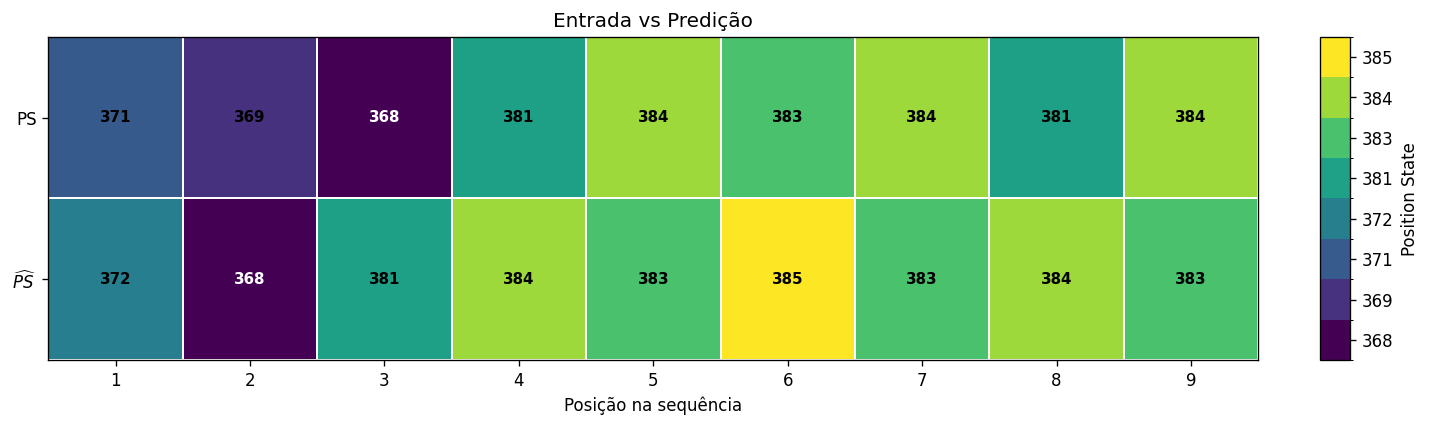

In [118]:
plot_tokens_vs_predictions_annotated(full_fwd)